# Лабораторная работа №2. Свёрточные нейронные сети
## Классификация дорожных знаков (GTSRB), AlexNet, пулинги, карты признаков

**Цель:** построить и обучить свёрточные сети для классификации изображений, побороть переобучение и недообучение, оценить экономию параметров при замене крупных ядер стопкой малых, доказать эквивариантность свёртки к сдвигу, реализовать транспонированную свёртку («деконволюцию») и вывести формулы размеров/рецептивного поля.

### Задание и где оно выполнено

| № | Пункт задания | Баллы | Раздел ноутбука |
|---|---|---|---|
| 0 | Собственная CNN со своей архитектурой | — | 6 |
| 1 | Архитектура известной модели (**AlexNet**, из рейтинга) | — | 7 |
| 2 | Обучение моделей для классификации, борьба с переобучением/недообучением | — | 6–8 |
| 2.1 | Валидация модели классификации | 5 | 4, 6–8 |
| 3 | Снижение параметров и рост числа операций при замене ядра стопкой малых (k1=93, k2=60, k3=0) | 7 | 9 |
| 4 | Доказательство эквивариантности свёртки | 8 | 10 |
| 5 | Реализация деконволюции (транспонированной свёртки) | 9 | 11 |
| 6 | Ответ и объяснение формул (все четыре) | 10 | 12 |

**Известная модель** — AlexNet (колонка «arch lab 2» рейтинга). Значения из рейтинга: **k1 = 93, k2 = 60, k3 = 0**. Это не похоже на реальные размеры ядра (ядро 0 невозможно, 93×93 больше любой карты признаков AlexNet), но по условию задания расчёт выполнен именно для них, см. раздел 9.

**Данные:** GTSRB (German Traffic Sign Recognition Benchmark) — фотографии немецких дорожных знаков, 43 класса. Подробное описание в разделе 1.

In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
import os, sys, math, json, time, random, platform, importlib.metadata, itertools, warnings
os.environ.setdefault('TORCH_HOME', str(Path('.cache/torch').resolve()))
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, models
from PIL import Image
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

SMOKE = os.environ.get('LAB2_SMOKE') == '1'   # быстрый прогон для проверки кода; в обычном запуске выключен


@dataclass
class Config:
    data_root: str = 'data'
    result_dir: str = 'results'
    cache_dir: str = '.cache'
    img_size: int = 64
    n_classes: int = 43
    split_seed: int = 42
    seeds: tuple = (42, 43, 44)
    val_folds: int = 5            # 1 из 5 групп -> около 20% train уходит в validation
    batch_size: int = 128
    mlp_epochs: int = 15
    cnn_epochs: int = 25
    cnn_patience: int = 6
    under_epochs: int = 4
    over_epochs: int = 20
    alex_epochs: int = 20
    alex_patience: int = 6
    ft_epochs: int = 8
    alex_size: int = 224          # вход AlexNet: изображения 64×64 увеличиваются внутри модели
    smoke: bool = SMOKE


cfg = Config()
if cfg.smoke:
    cfg.mlp_epochs = cfg.cnn_epochs = cfg.under_epochs = cfg.over_epochs = cfg.alex_epochs = cfg.ft_epochs = 2
    cfg.cnn_patience = cfg.alex_patience = 2
    cfg.seeds = (42, 43)

RES = Path(cfg.result_dir + ('_smoke' if cfg.smoke else '')); RES.mkdir(exist_ok=True)
CACHE = Path(cfg.cache_dir); CACHE.mkdir(exist_ok=True)
(CACHE / 'ckpt').mkdir(exist_ok=True)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')


def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(cfg.split_seed)
print('device:', device, '| python', platform.python_version(), '| torch', torch.__version__, '| torchvision', torchvision.__version__)
print('режим:', 'SMOKE (быстрая проверка)' if cfg.smoke else 'полный прогон')

device: mps | python 3.13.7 | torch 2.8.0 | torchvision 0.23.0
режим: полный прогон


## 1. Данные: GTSRB — немецкие дорожные знаки

**GTSRB (German Traffic Sign Recognition Benchmark)** — соревнование по классификации изображений на конференции IJCNN 2011 (Stallkamp, Schlipsing, Salmen, Igel; Рурский университет Бохума). Это нишевый, но «живой» датасет: реальные фотографии знаков с автомобиля в разных погодных и световых условиях.

| Свойство | Значение |
|---|---|
| Задача | многоклассовая классификация одного изображения |
| Классы | 43 (ограничения скорости, запреты, предупреждения, предписания) |
| Объём | в версии, которую скачивает `torchvision`: **26 640 train** и **12 630 test** (оригинальный конкурс заявляет 39 209 train; здесь используется то, что реально лежит в архиве `GTSRB-Training_fixed.zip`) |
| Формат | цветные RGB, файлы `.ppm`; стороны по описанию конкурса от ~15 до ~250 px, в загруженной версии (выборка 1 из 20) — от 25 до 134 px, медиана 39; квадратных лишь около четверти |
| Дисбаланс | сильный: от 150 до 1 500 изображений на класс в train (10 : 1) |
| Структура train | 888 *треков*: каждый физический знак снят серией ~30 почти одинаковых кадров |

**Особенности, важные для постановки эксперимента:**
- Числа выше проверены при загрузке (раздел 1); при другой версии архива они могут отличаться.
- Кадры одного трека почти неотличимы, поэтому случайное разбиение по кадрам даёт **утечку** (почти копии знака попадают и в train, и в validation). Validation выделяется из train **группами по треку** — так же, как в лабе 1 дубликаты группировались при разбиении.
- Дисбаланс классов: одной accuracy мало, дополнительно считается **macro-F1** и смотрятся худшие классы.
- Горизонтальное отражение нельзя использовать как аугментацию: оно меняет смысл знаков («поворот налево» ↔ «поворот направо»).
- Изображения разных размеров приводятся к **64×64** (AlexNet дополнительно увеличивает их до 224×224 внутри модели, раздел 7).

**Источник и условия.** Официальная страница: <https://benchmark.ini.rub.de/> (во время подготовки ноутбука сайт не открывался; зеркало: Zenodo, DOI 10.5281/zenodo.13741936). Явная свободная лицензия на странице зеркала не указана; датасет создан для исследовательских целей, перед публикацией данных заново проверьте условия на официальной странице. Загружается автоматически через `torchvision.datasets.GTSRB`.

**Ссылки:** J. Stallkamp, M. Schlipsing, J. Salmen, C. Igel. *The German Traffic Sign Recognition Benchmark: A multi-class classification competition.* IJCNN 2011. Они же: *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition.* Neural Networks 32 (2012).

**Ограничения оценки.** Один раздел train/test от организаторов; test используется один раз. Все снимки сделаны в Германии, перенос на знаки других стран не проверяется. Все знаки приводятся к квадрату 64×64 без обрезки по рамке, поэтому у части знаков остаётся фон.

In [2]:
ds_train = datasets.GTSRB(cfg.data_root, split='train', download=True)
ds_test = datasets.GTSRB(cfg.data_root, split='test', download=True)
print('train:', len(ds_train), '| test:', len(ds_test))
train_paths = [str(p) for p, _ in ds_train._samples]
train_y = np.array([int(t) for _, t in ds_train._samples])
test_paths = [str(p) for p, _ in ds_test._samples]
test_y = np.array([int(t) for _, t in ds_test._samples])
assert len(set(train_y)) == cfg.n_classes and len(set(test_y)) == cfg.n_classes
# трек = имя файла вида <трек>_<кадр>.ppm в папке класса
train_track = np.array([f'{c}_{Path(p).name.split("_")[0]}' for p, c in zip(train_paths, train_y)])
print('классов:', cfg.n_classes, '| треков в train:', len(set(train_track)), '| кадров на трек: ~', round(len(train_y) / len(set(train_track)), 1))
print('пример пути:', train_paths[0])

train: 26640 | test: 12630
классов: 43 | треков в train: 888 | кадров на трек: ~ 30.0
пример пути: data/gtsrb/GTSRB/Training/00000/00000_00000.ppm


## 2. Первичный анализ данных
Графики строятся по всему train и описывают данные. Выбор моделей далее использует только validation, нормализация обучается только на train.

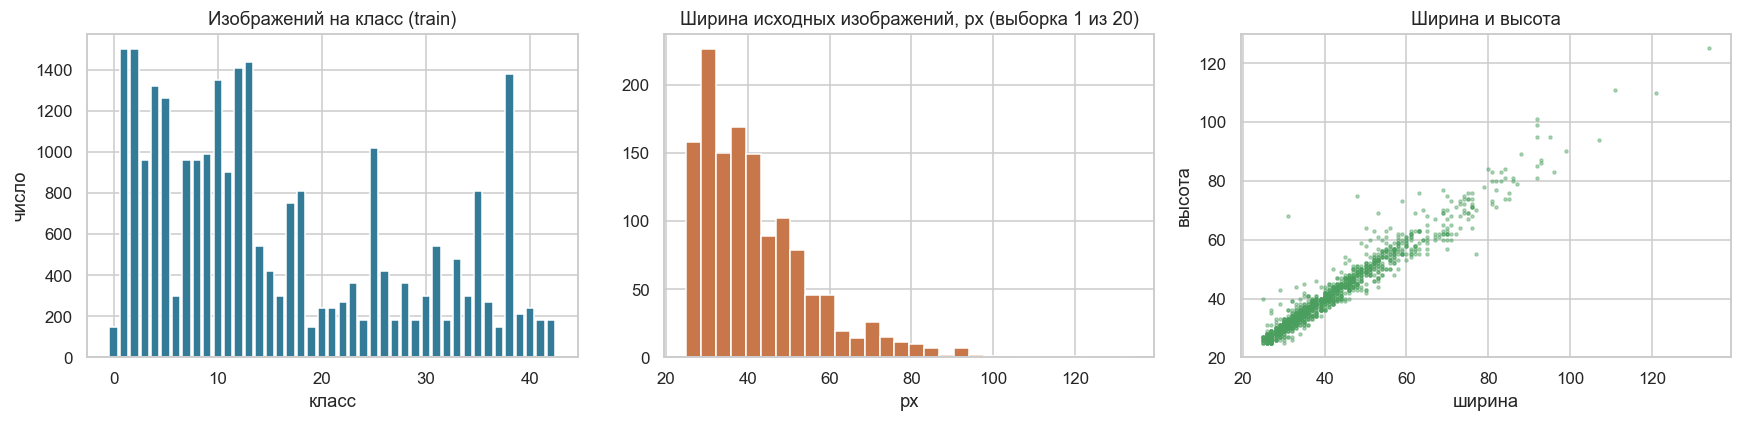

классов: 43 | min/max изображений в классе: 150 / 1500 (отношение 10.0:1)
ширина: медиана 39, min 25, max 134; доля квадратных: 0.24


In [3]:
sizes = []
for p in train_paths[::20]:
    with Image.open(p) as im:
        sizes.append(im.size)
sizes = np.array(sizes)
counts = pd.Series(train_y).value_counts().sort_index()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(counts.index, counts.values, color='#347b98')
ax[0].set(title='Изображений на класс (train)', xlabel='класс', ylabel='число')
ax[1].hist(sizes[:, 0], bins=30, color='#c8774b')
ax[1].set(title='Ширина исходных изображений, px (выборка 1 из 20)', xlabel='px')
ax[2].scatter(sizes[:, 0], sizes[:, 1], s=4, alpha=.4, color='#4b9f5e')
ax[2].set(title='Ширина и высота', xlabel='ширина', ylabel='высота')
plt.tight_layout(); plt.savefig(RES / 'eda_overview.png'); plt.show()
print(f'классов: {len(counts)} | min/max изображений в классе: {counts.min()} / {counts.max()} (отношение {counts.max() / counts.min():.1f}:1)')
print(f'ширина: медиана {np.median(sizes[:, 0]):.0f}, min {sizes[:, 0].min()}, max {sizes[:, 0].max()}; доля квадратных: {(sizes[:, 0] == sizes[:, 1]).mean():.2f}')

## 3. Загрузка в память и разбиение
Все изображения один раз приводятся к `64×64` (билинейная интерполяция, `uint8`) и хранятся тензором. Результат кэшируется в `.cache/`, чтобы повторный запуск не пересчитывал.

**Разбиение train → train/validation.** `StratifiedGroupKFold` с группами «класс+трек»: все кадры трека остаются по одну сторону, доли классов сохраняются. Одна из 5 групп (≈20%) — validation. Семь групп не подошли: у самых редких классов всего 5 треков, и в validation часть классов отсутствовала. Официальный test (12 630) не участвует в выборе моделей и считается один раз в конце.

In [4]:
def load_resized(paths, size):
    out = np.empty((len(paths), size, size, 3), dtype=np.uint8)
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            out[i] = np.asarray(im.convert('RGB').resize((size, size), Image.BILINEAR))
    return out


cache_file = CACHE / f'gtsrb_{cfg.img_size}.npz'
if cache_file.exists():
    z = np.load(cache_file)
    X_all, X_test_np = z['train'], z['test']
else:
    t0 = time.time()
    X_all = load_resized(train_paths, cfg.img_size)
    X_test_np = load_resized(test_paths, cfg.img_size)
    np.savez(cache_file, train=X_all, test=X_test_np)
    print(f'ресайз и кэш: {time.time() - t0:.0f} с')
print('train', X_all.shape, 'test', X_test_np.shape)

sgkf = StratifiedGroupKFold(n_splits=cfg.val_folds, shuffle=True, random_state=cfg.split_seed)
_, val_idx = next(sgkf.split(np.zeros(len(train_y)), train_y, groups=train_track))
is_val = np.zeros(len(train_y), dtype=bool); is_val[val_idx] = True
tr_idx = np.where(~is_val)[0]
assert not set(train_track[tr_idx]) & set(train_track[val_idx]), 'утечка треков'
assert set(train_y[tr_idx]) == set(train_y[val_idx]) == set(range(cfg.n_classes))
print(f'train {len(tr_idx)} | validation {len(val_idx)} | test {len(test_y)}; общих треков train/val: 0')
pd.DataFrame({'path': train_paths, 'label': train_y, 'track': train_track, 'split': np.where(is_val, 'val', 'train')}).to_csv(RES / 'split.csv', index=False)

if cfg.smoke:   # уменьшенные подвыборки для проверки кода
    rng = np.random.default_rng(0)
    tr_idx = rng.choice(tr_idx, 3000, replace=False); val_idx = rng.choice(val_idx, 800, replace=False)
    X_test_np, test_y = X_test_np[:1000], test_y[:1000]

to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()
Xtr, ytr = to_t(X_all[tr_idx]).to(device), torch.from_numpy(train_y[tr_idx]).to(device)
Xva, yva = to_t(X_all[val_idx]).to(device), torch.from_numpy(train_y[val_idx]).to(device)
Xte, yte = to_t(X_test_np).to(device), torch.from_numpy(test_y).to(device)
TR_MEAN = (Xtr.float() / 255).mean((0, 2, 3)).cpu()
TR_STD = (Xtr.float() / 255).std((0, 2, 3)).cpu()
print('mean/std по train:', TR_MEAN.numpy().round(3), TR_STD.numpy().round(3))

train (26640, 64, 64, 3) test (12630, 64, 64, 3)
train 21300 | validation 5340 | test 12630; общих треков train/val: 0


mean/std по train: [0.342 0.313 0.321] [0.276 0.264 0.27 ]


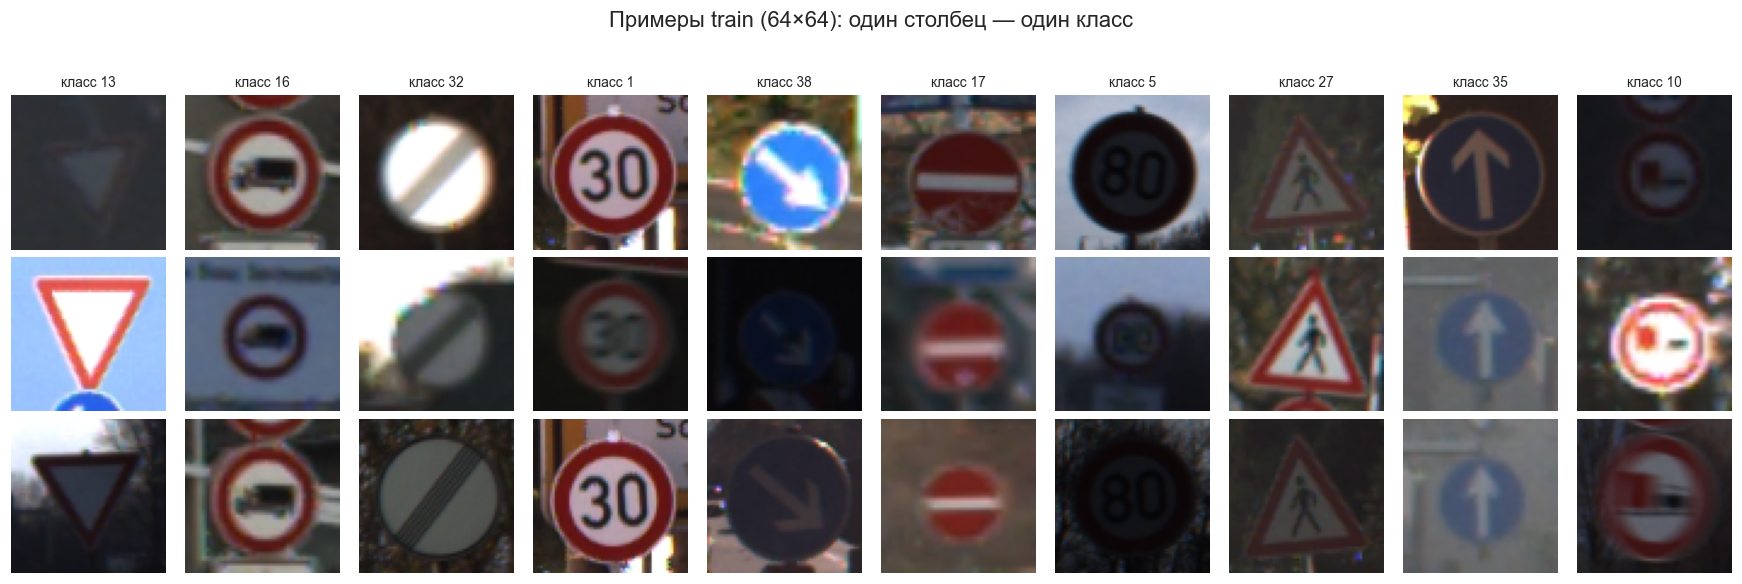

In [5]:
fig, axes = plt.subplots(3, 10, figsize=(16, 5.2))
rng = np.random.default_rng(1)
classes_show = rng.choice(cfg.n_classes, 10, replace=False)
for j, c in enumerate(classes_show):
    ii = np.where(train_y[tr_idx] == c)[0]
    for r in range(3):
        axes[r, j].imshow(X_all[tr_idx][rng.choice(ii)]); axes[r, j].axis('off')
    axes[0, j].set_title(f'класс {c}', fontsize=9)
plt.suptitle('Примеры train (64×64): один столбец — один класс', y=1.02)
plt.tight_layout(); plt.savefig(RES / 'eda_examples.png', bbox_inches='tight'); plt.show()

## 4. Общая инфраструктура обучения и валидации

- **Нормализация** — слой внутри модели (`Normalize`), поэтому данные в памяти остаются `uint8`. Для своих моделей используются mean/std по train, для предобученной AlexNet — константы ImageNet.
- **Аугментации** (на устройстве, батчем): поворот ±10°, сдвиг ±10%, масштаб ±10%, яркость и контраст ±20%. Отражений нет.
- **Оптимизатор:** AdamW, косинусный `scheduler`, **early stopping по validation macro-F1** с восстановлением весов лучшей эпохи.
- **Метрики validation:** accuracy и macro-F1 (классы несбалансированы). Метрики train за эпоху — скользящие по батчам (с аугментацией и включённым Dropout), поэтому они занижены относительно «чистой» оценки на train.
- Результаты каждого запуска сохраняются (`results/history_*.csv`, веса в `.cache/ckpt`), повторный запуск ноутбука использует готовые прогоны.

In [6]:
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.as_tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer('std', torch.as_tensor(std, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x):
        return (x - self.mean) / self.std


def augment(x, rot=10., shift=0.1, scale=0.1, bright=0.2, contrast=0.2):
    """Аффинные преобразования + яркость/контраст. x: B×3×H×W в [0, 1]. Без горизонтального отражения."""
    B = x.shape[0]; dev = x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1
    ang = u() * rot * math.pi / 180
    sc = 1 + u() * scale
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    tx, ty = u() * shift * 2, u() * shift * 2
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    b = (u() * bright).view(B, 1, 1, 1); c = (1 + u() * contrast).view(B, 1, 1, 1)
    m = x.mean((1, 2, 3), keepdim=True)
    return ((x - m) * c + m + b).clamp(0, 1)


@torch.no_grad()
def predict(model, X, bs=512):
    model.eval()
    return torch.cat([model(X[i:i + bs].float() / 255).float().cpu() for i in range(0, len(X), bs)])


def metrics_from_logits(logits, y):
    y = y.cpu().numpy(); p = logits.argmax(1).numpy()
    return dict(acc=accuracy_score(y, p), f1=f1_score(y, p, average='macro'), loss=F.cross_entropy(logits, torch.as_tensor(y)).item())


def n_params(m):
    return sum(p.numel() for p in m.parameters())


def fit(model, name, lr=1e-3, wd=1e-4, epochs=20, patience=6, aug=True, bs=None, param_groups=None, early_stop=True, seed=42, verbose=True):
    """Обучение с валидацией. Возвращает (history DataFrame, модель с весами лучшей эпохи)."""
    bs = bs or cfg.batch_size
    hist_path, ckpt = RES / f'history_{name}.csv', CACHE / 'ckpt' / f'{"smoke_" if cfg.smoke else ""}{name}.pt'
    if hist_path.exists() and ckpt.exists():
        h = pd.read_csv(hist_path)
        model.load_state_dict(torch.load(ckpt, map_location='cpu')); model.to(device)
        if verbose:
            print(f'[{name}] загружен готовый прогон (история обучения из results/history_{name}.csv):')
            print(h[['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1', 'sec']].round(3).to_string(index=False))
        return h, model
    set_seed(seed)
    model.to(device)
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, bad, rows = -1, None, 0, []
    n = len(Xtr)
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        perm = torch.randperm(n, device=device)
        tl = tc = 0.
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb = Xtr[idx].float() / 255; yb = ytr[idx]
            if aug: xb = augment(xb)
            out = model(xb); loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tl += loss.item() * len(idx); tc += (out.argmax(1) == yb).sum().item()
        sched.step()
        vm = metrics_from_logits(predict(model, Xva), yva)
        rows.append(dict(epoch=ep, train_loss=tl / n, train_acc=tc / n, val_loss=vm['loss'], val_acc=vm['acc'], val_f1=vm['f1'], lr=opt.param_groups[0]['lr'], sec=time.time() - t0))
        if verbose: print(f'[{name}] ep {ep:02d} train loss {tl / n:.3f} acc {tc / n:.3f} | val loss {vm["loss"]:.3f} acc {vm["acc"]:.3f} F1 {vm["f1"]:.3f} | {time.time() - t0:.1f} c')
        if vm['f1'] > best:
            best, bad = vm['f1'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if early_stop and bad >= patience:
                if verbose: print(f'[{name}] early stopping на эпохе {ep}'); break
    model.load_state_dict(best_state)
    h = pd.DataFrame(rows)
    h.to_csv(hist_path, index=False); torch.save(best_state, ckpt)
    return h, model


def best_row(h):
    return h.loc[h.val_f1.idxmax()]

## 5. Базовые модели

### 5.1. Константный прогноз и MLP
Нижняя граница — прогноз самого частого класса. Затем **MLP** на тех же пикселях (как в лабе 1 — полносвязная сеть, без аугментаций): `12288 → 512 → 128 → 43`. Показывает, что даёт сама свёрточная структура.

In [7]:
const_pred = torch.full((len(yva),), int(torch.bincount(ytr).argmax().item()), device=device)
const_f1 = f1_score(yva.cpu(), const_pred.cpu(), average='macro'); const_acc = accuracy_score(yva.cpu(), const_pred.cpu())
print(f'константный прогноз (самый частый класс): val acc {const_acc:.3f}, macro-F1 {const_f1:.4f}')


def make_mlp(p_drop=0.3):
    return nn.Sequential(Normalize(TR_MEAN, TR_STD), nn.Flatten(), nn.Linear(3 * cfg.img_size ** 2, 512), nn.ReLU(), nn.Dropout(p_drop),
                         nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, cfg.n_classes))


mlp = make_mlp()
print('параметров MLP:', f'{n_params(mlp):,}')
h_mlp, mlp = fit(mlp, 'mlp', lr=1e-3, wd=1e-4, epochs=cfg.mlp_epochs, patience=5, aug=False)
print(best_row(h_mlp)[['epoch', 'train_acc', 'val_acc', 'val_f1']].to_dict())

константный прогноз (самый частый класс): val acc 0.056, macro-F1 0.0025
параметров MLP: 6,363,179
[mlp] загружен готовый прогон (история обучения из results/history_mlp.csv):
 epoch  train_loss  train_acc  val_loss  val_acc  val_f1   sec
     1       2.034      0.458     1.578    0.571   0.463 1.175
     2       0.873      0.740     1.240    0.680   0.604 0.924
     3       0.627      0.815     1.222    0.704   0.622 0.977
     4       0.471      0.858     1.209    0.724   0.657 0.977
     5       0.394      0.883     1.139    0.726   0.653 0.960
     6       0.314      0.906     1.127    0.757   0.697 1.002
     7       0.258      0.921     0.966    0.798   0.715 0.977
     8       0.204      0.938     0.989    0.783   0.698 0.971
     9       0.165      0.951     1.063    0.796   0.728 0.950
    10       0.128      0.962     1.016    0.799   0.737 1.108
    11       0.098      0.972     0.907    0.824   0.755 0.966
    12       0.078      0.978     0.900    0.827   0.754 1.049
    1

## 6. Пункт 0: собственная CNN. Пулинги. Недообучение и переобучение

### 6.1. Архитектура
Четыре блока `Conv3×3 → BatchNorm → ReLU → Pool2×2` с числом каналов `w, 2w, 4w, 8w`; после четырёх пулингов карта `64→32→16→8→4`, затем `Flatten → Dropout → Linear(8w·16, 128) → ReLU → Dropout → Linear(128, 43)`. При `w=32` около 0.9 млн параметров (для сравнения: AlexNet — десятки миллионов).

Свёртка 3×3 выбрана потому, что стопка таких свёрток покрывает любое рецептивное поле при меньшем числе параметров (раздел 10). BatchNorm стабилизирует обучение, Dropout и аугментации борются с переобучением.

In [8]:
class CNN(nn.Module):
    def __init__(self, pool='max', width=32, p_drop=0.3, bn=True, n_classes=cfg.n_classes):
        super().__init__()
        self.norm = Normalize(TR_MEAN, TR_STD)
        Pool = nn.MaxPool2d if pool == 'max' else nn.AvgPool2d
        ch, layers, c_in = [width, 2 * width, 4 * width, 8 * width], [], 3
        for c in ch:
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=not bn)] + ([nn.BatchNorm2d(c)] if bn else []) + [nn.ReLU(inplace=True), Pool(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        side = cfg.img_size // 16
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(c_in * side * side, 128), nn.ReLU(inplace=True), nn.Dropout(p_drop), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.classifier(self.features(self.norm(x)))


print('параметров CNN (w=32):', f'{n_params(CNN()):,}', '| MLP:', f'{n_params(make_mlp()):,}')

параметров CNN (w=32): 918,859 | MLP: 6,363,179


### 6.2. Сравнение пулингов: max и average
Одна и та же сеть, меняется только `Pool2×2`. Три seed (42–44), выбор по среднему validation macro-F1, как в лабе 1. Max-pooling оставляет самый сильный отклик в окне (устойчив к малым сдвигам, выделяет «наличие признака»); average — усредняет окно (сглаживает, но размывает редкие сильные признаки).

[cnn_max_s42] загружен готовый прогон (история обучения из results/history_cnn_max_s42.csv):
 epoch  train_loss  train_acc  val_loss  val_acc  val_f1   sec
     1       2.420      0.317     1.226    0.601   0.405 4.881
     2       0.991      0.682     0.462    0.867   0.737 3.452
     3       0.565      0.821     0.284    0.916   0.859 3.422
     4       0.406      0.876     0.234    0.931   0.878 3.467
     5       0.322      0.901     0.148    0.966   0.943 3.463
     6       0.270      0.921     0.130    0.967   0.944 3.399
     7       0.234      0.929     0.129    0.965   0.945 3.391
     8       0.203      0.938     0.096    0.976   0.953 3.490
     9       0.192      0.943     0.092    0.978   0.955 3.437
    10       0.170      0.949     0.107    0.978   0.955 3.335
    11       0.155      0.954     0.086    0.981   0.959 3.381
    12       0.140      0.959     0.087    0.981   0.959 3.362
    13       0.129      0.962     0.061    0.986   0.960 3.379
    14       0.123      0

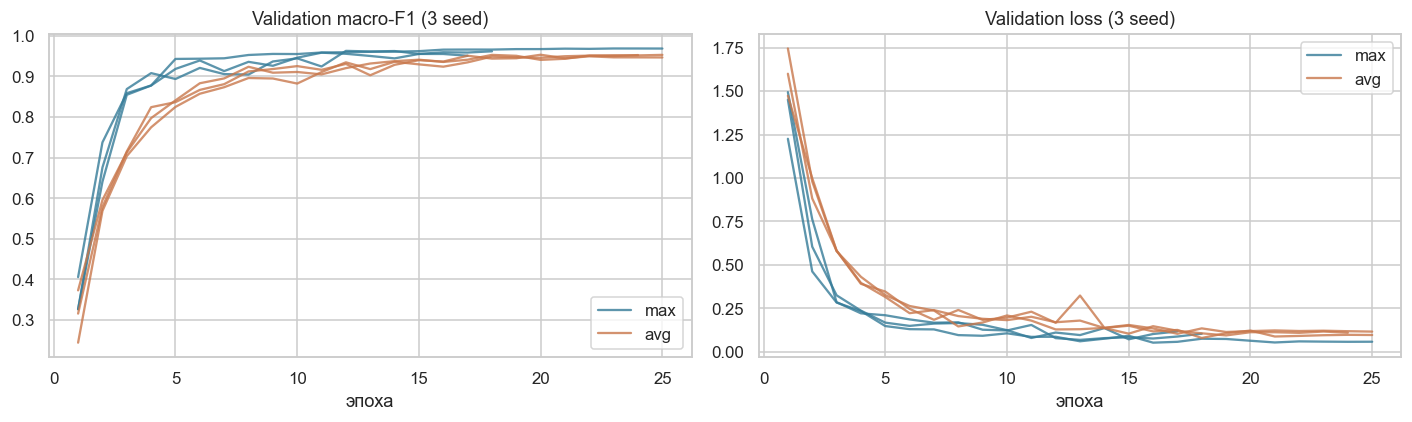

In [9]:
cnn_runs = {}
rows = []
for pool in ('max', 'avg'):
    for seed in cfg.seeds:
        name = f'cnn_{pool}_s{seed}'
        h, m = fit(CNN(pool), name, lr=1e-3, wd=1e-4, epochs=cfg.cnn_epochs, patience=cfg.cnn_patience, aug=True, seed=seed)
        b = best_row(h); cnn_runs[name] = (h, m)
        rows.append(dict(pool=pool, seed=seed, best_epoch=int(b.epoch), train_acc=b.train_acc, val_acc=b.val_acc, val_f1=b.val_f1, val_loss=b.val_loss, sec_per_epoch=h.sec.mean()))
pool_runs = pd.DataFrame(rows)
pool_runs.to_csv(RES / 'pooling_runs.csv', index=False)
pool_summary = pool_runs.groupby('pool').agg(val_f1_mean=('val_f1', 'mean'), val_f1_std=('val_f1', 'std'), val_acc_mean=('val_acc', 'mean'), best_epoch=('best_epoch', 'mean'), sec_per_epoch=('sec_per_epoch', 'mean'))
pool_summary.to_csv(RES / 'pooling_summary.csv')
print(pool_summary.round(4))
best_pool = pool_summary.val_f1_mean.idxmax()
print('выбранный пулинг по validation macro-F1:', best_pool)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for pool, col in (('max', '#347b98'), ('avg', '#c8774b')):
    for k, seed in enumerate(cfg.seeds):
        h = cnn_runs[f'cnn_{pool}_s{seed}'][0]
        ax[0].plot(h.epoch, h.val_f1, color=col, alpha=.8, label=f'{pool}' if k == 0 else None)
        ax[1].plot(h.epoch, h.val_loss, color=col, alpha=.8, label=f'{pool}' if k == 0 else None)
ax[0].set(title='Validation macro-F1 (3 seed)', xlabel='эпоха'); ax[1].set(title='Validation loss (3 seed)', xlabel='эпоха')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.savefig(RES / 'pooling_comparison.png'); plt.show()

### 6.3. Борьба с недообучением и переобучением (пункт 2)
Три режима одной архитектуры:
1. **Недообучение:** предельно узкая сеть (`w=1`: каналы 1, 2, 4, 8), малая скорость обучения и мало эпох. Ожидаемо — высокая ошибка уже на train.
2. **Переобучение:** широкая сеть (`w=48`), без аугментаций, без Dropout, `weight decay = 0`, без early stopping — сеть запоминает train.
3. **Исправленная версия:** `w=32`, аугментации, Dropout 0.3, `weight decay 1e-4`, косинусный `scheduler`, early stopping — это модель раздела 6.2 с seed 42.

Диагностика: **разрыв** `train − validation` и динамика validation loss (рост при падении train loss — признак переобучения). Метрики train — скользящие по эпохе.

[cnn_under] ep 01 train loss 3.307 acc 0.148 | val loss 3.083 acc 0.189 F1 0.078 | 3.5 c


[cnn_under] ep 02 train loss 2.593 acc 0.317 | val loss 2.417 acc 0.325 F1 0.159 | 1.2 c


[cnn_under] ep 03 train loss 2.043 acc 0.437 | val loss 2.138 acc 0.405 F1 0.224 | 1.2 c


[cnn_under] ep 04 train loss 1.852 acc 0.480 | val loss 2.067 acc 0.423 F1 0.249 | 1.4 c
[cnn_over] загружен готовый прогон (история обучения из results/history_cnn_over.csv):
 epoch  train_loss  train_acc  val_loss  val_acc  val_f1   sec
     1       1.277      0.646     0.474    0.864   0.766 6.086
     2       0.053      0.990     0.321    0.911   0.858 5.529
     3       0.017      0.997     0.258    0.932   0.876 5.627
     4       0.006      0.999     0.218    0.937   0.876 5.496
     5       0.004      1.000     0.183    0.953   0.911 5.477
     6       0.001      1.000     0.175    0.955   0.908 5.986
     7       0.000      1.000     0.181    0.953   0.905 6.457
     8       0.000      1.000     0.171    0.954   0.909 6.308
     9       0.000      1.000     0.163    0.956   0.912 6.474
    10       0.000      1.000     0.165    0.955   0.913 6.132
    11       0.000      1.000     0.163    0.955   0.913 5.898
    12       0.000      1.000     0.162    0.955   0.914 5.617
    1

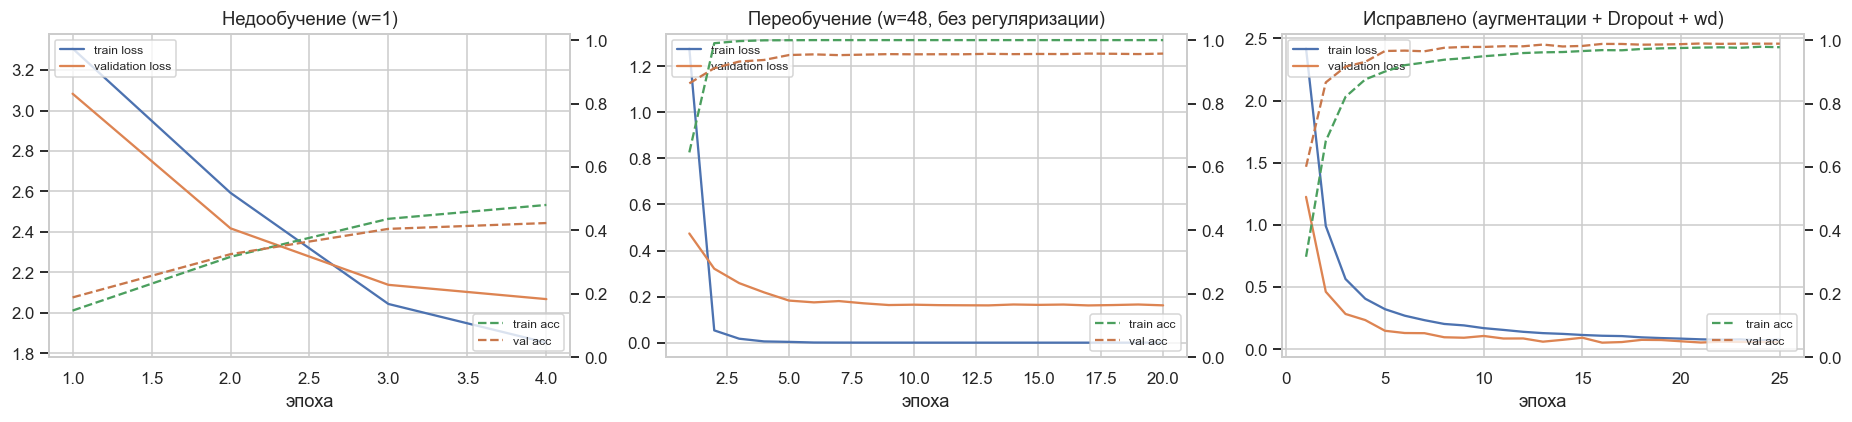

            режим  epochs  best_epoch  train_acc_best  val_acc_best  val_f1_best  gap_acc_best  val_loss_min  val_loss_last  train_loss_last
 недообучение w=1       4           4          0.4805        0.4234       0.2487        0.0571        2.0672         2.0672           1.8518
переобучение w=48      20          18          1.0000        0.9569       0.9152        0.0431        0.1617         0.1621           0.0001
  исправлено w=32      25          23          0.9758        0.9888       0.9687       -0.0130        0.0527         0.0582           0.0769


In [10]:
h_under, m_under = fit(CNN(best_pool, width=1, p_drop=0.0), 'cnn_under', lr=3e-4, wd=0, epochs=cfg.under_epochs, patience=99, aug=False, early_stop=False)
h_over, m_over = fit(CNN(best_pool, width=48, p_drop=0.0), 'cnn_over', lr=1e-3, wd=0, epochs=cfg.over_epochs, patience=99, aug=False, early_stop=False)
h_fix = cnn_runs[f'cnn_{best_pool}_s42'][0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (h, t) in zip(ax, ((h_under, 'Недообучение (w=1)'), (h_over, 'Переобучение (w=48, без регуляризации)'), (h_fix, 'Исправлено (аугментации + Dropout + wd)'))):
    a.plot(h.epoch, h.train_loss, label='train loss'); a.plot(h.epoch, h.val_loss, label='validation loss')
    a2 = a.twinx(); a2.plot(h.epoch, h.train_acc, '--', color='#4b9f5e', label='train acc'); a2.plot(h.epoch, h.val_acc, '--', color='#c8774b', label='val acc')
    a2.set_ylim(0, 1.02); a.set(title=t, xlabel='эпоха'); a.legend(loc='upper left', fontsize=8); a2.legend(loc='lower right', fontsize=8); a2.grid(False)
plt.tight_layout(); plt.savefig(RES / 'under_over_fit.png'); plt.show()

fit_rows = []
for label, h, w, p in (('недообучение w=1', h_under, 1, 0), ('переобучение w=48', h_over, 48, 0), ('исправлено w=32', h_fix, 32, 0.3)):
    b = best_row(h); last = h.iloc[-1]
    fit_rows.append(dict(режим=label, epochs=len(h), best_epoch=int(b.epoch), train_acc_best=b.train_acc, val_acc_best=b.val_acc, val_f1_best=b.val_f1, gap_acc_best=b.train_acc - b.val_acc,
                         val_loss_min=h.val_loss.min(), val_loss_last=last.val_loss, train_loss_last=last.train_loss))
fit_table = pd.DataFrame(fit_rows); fit_table.to_csv(RES / 'under_over_summary.csv', index=False)
print(fit_table.round(4).to_string(index=False))

## 7. Пункт 1: AlexNet

### 7.1. Архитектура
AlexNet (Krizhevsky et al., 2012) в современном варианте PyTorch: 5 свёрток `11×11/4 → 5×5 → 3×3 → 3×3 → 3×3` (64, 192, 384, 256, 256 каналов), три `MaxPool 3×3/2`, `AdaptiveAvgPool 6×6` (реализован повтором пикселей, это точно совпадает с `nn.AdaptiveAvgPool2d((6, 6))` для карт 1, 2, 3 и 6, см. проверку ниже), классификатор `Dropout → 9216→4096 → ReLU → Dropout → 4096→4096 → ReLU → 4096→классы`. Класс написан вручную, имена параметров совпадают с `torchvision`, поэтому в него загружаются предобученные веса. Ниже проверяется, что число параметров и формы тензоров совпадают с эталоном.

**Вход.** Оригинальная AlexNet рассчитана на 224×224. На 64×64 после `features` карта получается `256×1×1` (ниже напечатаны размеры), то есть пространственная структура схлопывается. Поэтому все AlexNet-модели получают картинку, **увеличенную внутри модели билинейно с 64 до 224** (в памяти данные остаются 64×64; новых деталей это не добавляет, но возвращает слоям AlexNet привычные масштабы). Для сравнения в разделе 7.4 приведены и прогоны со входом 64×64: выбор размера входа сделан по validation.

In [11]:
class AdaptiveAvgPool6(nn.Module):
    """AdaptiveAvgPool2d((6, 6)). Если сторона карты делит 6 (в т.ч. 1×1 -> 6×6), бин адаптивного усреднения содержит ровно один пиксель,
    и результат равен повторению пикселей; так считается быстро и без ограничений backend'а MPS. Иначе — стандартный adaptive pool."""
    def forward(self, x):
        h, w = x.shape[-2:]
        if 6 % h == 0 and 6 % w == 0:
            return x.repeat_interleave(6 // h, dim=2).repeat_interleave(6 // w, dim=3)
        return F.adaptive_avg_pool2d(x, (6, 6))


class AlexNet(nn.Module):
    def __init__(self, n_classes=1000, p_drop=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(kernel_size=3, stride=2))
        self.avgpool = AdaptiveAvgPool6()
        self.classifier = nn.Sequential(
            nn.Dropout(p=p_drop), nn.Linear(256 * 6 * 6, 4096), nn.ReLU(inplace=True),
            nn.Dropout(p=p_drop), nn.Linear(4096, 4096), nn.ReLU(inplace=True), nn.Linear(4096, n_classes))

    def forward(self, x):
        return self.classifier(torch.flatten(self.avgpool(self.features(x)), 1))


class WithNorm(nn.Module):
    """[увеличение до size×size] -> нормализация -> сеть. Для size=None увеличения нет."""
    def __init__(self, net, mean, std, size=None):
        super().__init__(); self.norm = Normalize(mean, std); self.net = net; self.size = size

    def resize(self, x):
        return x if self.size is None else F.interpolate(x, size=(self.size, self.size), mode='bilinear', align_corners=False)

    def forward(self, x):
        return self.net(self.norm(self.resize(x)))


ref = models.alexnet(weights=None)
mine = AlexNet(1000)
sd_ref, sd_mine = ref.state_dict(), mine.state_dict()
assert list(sd_ref) == list(sd_mine) and all(sd_ref[k].shape == sd_mine[k].shape for k in sd_ref), 'архитектура не совпала с torchvision'
assert n_params(ref) == n_params(mine)
print(f'AlexNet(1000 классов): {n_params(mine):,} параметров — совпадает с torchvision; ключи и формы тензоров совпадают')
for hw in (1, 2, 3, 6, 13):
    t_ = torch.randn(2, 4, hw, hw)
    assert torch.allclose(AdaptiveAvgPool6()(t_), nn.AdaptiveAvgPool2d((6, 6))(t_)), hw
print('AdaptiveAvgPool6 совпал с nn.AdaptiveAvgPool2d((6, 6)) на картах 1, 2, 3, 6, 13')
x_t = torch.randn(2, 3, 64, 64)
with torch.no_grad():
    for side in (64, cfg.alex_size):
        shape = torch.randn(1, 3, side, side)
        print(f'вход {side}×{side}, выход при 43 классах:', tuple(AlexNet(cfg.n_classes)(shape).shape))
        for i, layer in enumerate(AlexNet(cfg.n_classes).features):
            shape = layer(shape)
            if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
                print(f'  features[{i}] {layer.__class__.__name__:9s} -> {tuple(shape.shape[1:])}')
del ref, mine

AlexNet(1000 классов): 61,100,840 параметров — совпадает с torchvision; ключи и формы тензоров совпадают
AdaptiveAvgPool6 совпал с nn.AdaptiveAvgPool2d((6, 6)) на картах 1, 2, 3, 6, 13
вход 64×64, выход при 43 классах: (1, 43)


  features[0] Conv2d    -> (64, 15, 15)
  features[2] MaxPool2d -> (64, 7, 7)
  features[3] Conv2d    -> (192, 7, 7)
  features[5] MaxPool2d -> (192, 3, 3)
  features[6] Conv2d    -> (384, 3, 3)
  features[8] Conv2d    -> (256, 3, 3)
  features[10] Conv2d    -> (256, 3, 3)
  features[12] MaxPool2d -> (256, 1, 1)
вход 224×224, выход при 43 классах: (1, 43)


  features[0] Conv2d    -> (64, 55, 55)
  features[2] MaxPool2d -> (64, 27, 27)
  features[3] Conv2d    -> (192, 27, 27)
  features[5] MaxPool2d -> (192, 13, 13)
  features[6] Conv2d    -> (384, 13, 13)
  features[8] Conv2d    -> (256, 13, 13)
  features[10] Conv2d    -> (256, 13, 13)
  features[12] MaxPool2d -> (256, 6, 6)


### 7.2. AlexNet с нуля
Классическая AlexNet без BatchNorm. Параметры те же (AdamW, косинусный `scheduler`, аугментации, early stopping), заменён только последний слой на 43 класса.

In [12]:
def make_alex_scratch(size):
    return WithNorm(AlexNet(cfg.n_classes), TR_MEAN, TR_STD, size=None if size == 64 else size)


alex = make_alex_scratch(cfg.alex_size)
print(f'параметров AlexNet (43 класса), вход {cfg.alex_size}×{cfg.alex_size}:', f'{n_params(alex):,}')
h_alex, alex = fit(alex, 'alexnet_scratch', lr=5e-4, wd=1e-4, epochs=cfg.alex_epochs, patience=cfg.alex_patience, aug=True)
print(best_row(h_alex)[['epoch', 'train_acc', 'val_acc', 'val_f1']].to_dict())

параметров AlexNet (43 класса), вход 224×224: 57,180,011


[alexnet_scratch] ep 01 train loss 3.263 acc 0.106 | val loss 2.776 acc 0.219 F1 0.079 | 22.5 c


[alexnet_scratch] ep 02 train loss 2.172 acc 0.325 | val loss 1.672 acc 0.460 F1 0.239 | 21.5 c


[alexnet_scratch] ep 03 train loss 1.243 acc 0.588 | val loss 0.954 acc 0.706 F1 0.579 | 20.8 c


[alexnet_scratch] ep 04 train loss 0.619 acc 0.800 | val loss 0.387 acc 0.900 F1 0.805 | 20.8 c


[alexnet_scratch] ep 05 train loss 0.350 acc 0.896 | val loss 0.268 acc 0.934 F1 0.900 | 21.8 c


... (12 outputs left out)

[alexnet_scratch] ep 18 train loss 0.055 acc 0.984 | val loss 0.128 acc 0.975 F1 0.954 | 22.7 c


[alexnet_scratch] ep 19 train loss 0.049 acc 0.986 | val loss 0.132 acc 0.974 F1 0.953 | 22.5 c


[alexnet_scratch] ep 20 train loss 0.047 acc 0.987 | val loss 0.130 acc 0.974 F1 0.953 | 21.2 c


{'epoch': 18.0, 'train_acc': 0.984225352112676, 'val_acc': 0.9749063670411985, 'val_f1': 0.9538662814559785}


### 7.3. Fine-tuning предобученной AlexNet
По условию: если модель «с нуля» работает плохо, берём предобученную, меняем последние линейные слои и дообучаем. Здесь fine-tuning выполнен в любом случае для сравнения.

- Веса `IMAGENET1K_V1` загружаются в написанный выше класс (по именам ключей).
- **Заменены последние линейные слои:** `4096→4096` на `4096→1024` и `4096→1000` на `1024→43` (новая инициализация).
- Нормализация — ImageNet (mean `0.485, 0.456, 0.406`, std `0.229, 0.224, 0.225`), потому что веса получены на ней.
- Дифференцированные скорости: свёрточные слои `lr=1e-4` (дообучение), новая «голова» `lr=1e-3`.

In [13]:
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def make_alex_ft(size):
    net = AlexNet(1000)
    net.load_state_dict(models.AlexNet_Weights.IMAGENET1K_V1.get_state_dict(progress=False))
    net.classifier[4] = nn.Linear(4096, 1024)
    net.classifier[6] = nn.Linear(1024, cfg.n_classes)
    groups = [dict(params=net.features.parameters(), lr=1e-4), dict(params=net.classifier.parameters(), lr=1e-3)]
    return WithNorm(net, IMNET_MEAN, IMNET_STD, size=None if size == 64 else size), groups


alex_ft, groups = make_alex_ft(cfg.alex_size)
print(f'параметров fine-tuned AlexNet, вход {cfg.alex_size}×{cfg.alex_size}:', f'{n_params(alex_ft):,}')
h_ft, alex_ft = fit(alex_ft, 'alexnet_finetune', wd=1e-4, epochs=cfg.ft_epochs, patience=99, aug=True, param_groups=groups, early_stop=False)
print(best_row(h_ft)[['epoch', 'train_acc', 'val_acc', 'val_f1']].to_dict())

параметров fine-tuned AlexNet, вход 224×224: 44,461,931


[alexnet_finetune] ep 01 train loss 0.753 acc 0.781 | val loss 0.267 acc 0.924 F1 0.850 | 20.7 c


[alexnet_finetune] ep 02 train loss 0.170 acc 0.947 | val loss 0.236 acc 0.934 F1 0.882 | 21.7 c


[alexnet_finetune] ep 03 train loss 0.118 acc 0.964 | val loss 0.221 acc 0.940 F1 0.914 | 21.0 c


[alexnet_finetune] ep 04 train loss 0.089 acc 0.973 | val loss 0.195 acc 0.947 F1 0.907 | 21.0 c


[alexnet_finetune] ep 05 train loss 0.066 acc 0.980 | val loss 0.142 acc 0.966 F1 0.934 | 21.4 c


[alexnet_finetune] ep 06 train loss 0.048 acc 0.986 | val loss 0.170 acc 0.964 F1 0.940 | 22.0 c


[alexnet_finetune] ep 07 train loss 0.043 acc 0.987 | val loss 0.143 acc 0.966 F1 0.948 | 21.5 c


[alexnet_finetune] ep 08 train loss 0.034 acc 0.990 | val loss 0.148 acc 0.965 F1 0.945 | 21.1 c


{'epoch': 7.0, 'train_acc': 0.9870422535211267, 'val_acc': 0.9659176029962547, 'val_f1': 0.9476071276036335}


### 7.4. Размер входа AlexNet: 64×64 или 224×224
Сравнение тех же двух режимов (с нуля и fine-tuning) при подаче 64×64 без увеличения. Размер входа выбирается по validation macro-F1.

In [14]:
alex64 = make_alex_scratch(64)
h_alex64, alex64 = fit(alex64, 'alexnet_scratch_in64', lr=5e-4, wd=1e-4, epochs=cfg.alex_epochs, patience=cfg.alex_patience, aug=True)
alex_ft64, groups64 = make_alex_ft(64)
h_ft64, alex_ft64 = fit(alex_ft64, 'alexnet_finetune_in64', wd=1e-4, epochs=cfg.ft_epochs, patience=99, aug=True, param_groups=groups64, early_stop=False)
abl = pd.DataFrame([dict(режим=lab, вход=s, best_epoch=int(best_row(h).epoch), train_acc=best_row(h).train_acc, val_acc=best_row(h).val_acc, val_f1=best_row(h).val_f1, sec_per_epoch=h.sec.mean())
                    for lab, s, h in (('AlexNet с нуля', 64, h_alex64), ('AlexNet с нуля', cfg.alex_size, h_alex), ('AlexNet fine-tuning', 64, h_ft64), ('AlexNet fine-tuning', cfg.alex_size, h_ft))])
abl.to_csv(RES / 'alexnet_input_ablation.csv', index=False)
print(abl.round(4).to_string(index=False))
del alex64, alex_ft64
if device.type == 'mps': torch.mps.empty_cache()

[alexnet_scratch_in64] загружен готовый прогон (история обучения из results/history_alexnet_scratch_in64.csv):
 epoch  train_loss  train_acc  val_loss  val_acc  val_f1   sec
     1       3.124      0.112     2.433    0.237   0.070 6.783
     2       2.086      0.323     1.911    0.381   0.191 6.438
     3       1.690      0.427     1.694    0.452   0.246 6.684
     4       1.299      0.553     1.268    0.588   0.408 6.741
     5       0.995      0.658     1.151    0.649   0.529 6.686
     6       0.828      0.720     1.143    0.677   0.532 6.457
     7       0.650      0.782     0.952    0.722   0.607 6.263
     8       0.582      0.810     0.946    0.722   0.617 6.292
     9       0.468      0.851     0.781    0.781   0.681 6.346
    10       0.414      0.868     0.812    0.800   0.692 6.727
    11       0.341      0.892     0.745    0.807   0.713 6.494
    12       0.292      0.909     0.752    0.817   0.713 6.323
    13       0.245      0.925     0.810    0.802   0.711 6.824
    14 

[alexnet_finetune_in64] загружен готовый прогон (история обучения из results/history_alexnet_finetune_in64.csv):
 epoch  train_loss  train_acc  val_loss  val_acc  val_f1   sec
     1       1.749      0.500     1.527    0.575   0.474 5.387
     2       0.758      0.749     1.272    0.654   0.551 5.201
     3       0.514      0.829     1.228    0.684   0.586 5.210
     4       0.362      0.882     1.285    0.695   0.609 5.214
     5       0.279      0.908     1.194    0.722   0.629 5.321
     6       0.217      0.931     1.207    0.724   0.628 5.327
     7       0.172      0.945     1.265    0.732   0.631 5.244
     8       0.154      0.950     1.237    0.739   0.635 5.256
              режим  вход  best_epoch  train_acc  val_acc  val_f1  sec_per_epoch
     AlexNet с нуля    64          20     0.9615   0.8380  0.7505         6.6014
     AlexNet с нуля   224          18     0.9842   0.9749  0.9539        22.1735
AlexNet fine-tuning    64           8     0.9500   0.7386  0.6350         5.2

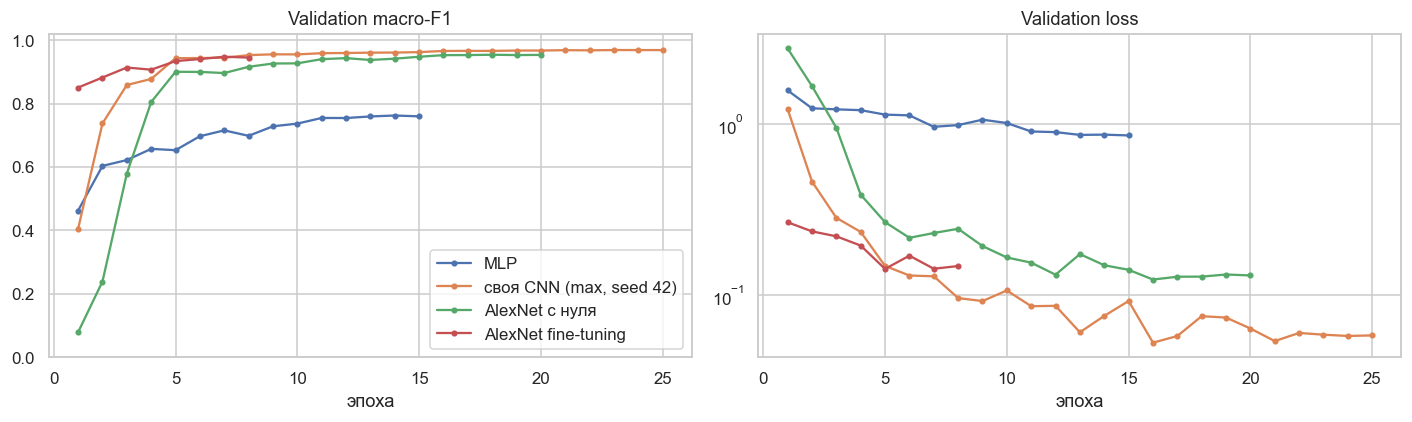

                 модель  параметров  best_epoch  train_acc  val_acc  val_f1
    константный прогноз           0           0        NaN   0.0562  0.0025
                    MLP     6363179          14     0.9868   0.8324  0.7623
своя CNN (max, seed 42)      918859          23     0.9758   0.9888  0.9687
         AlexNet с нуля    57180011          18     0.9842   0.9749  0.9539
    AlexNet fine-tuning    44461931           7     0.9870   0.9659  0.9476
лучшая по validation macro-F1: своя CNN (max, seed 42)


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, lab in ((h_mlp, 'MLP'), (h_fix, f'своя CNN ({best_pool}, seed 42)'), (h_alex, 'AlexNet с нуля'), (h_ft, 'AlexNet fine-tuning')):
    ax[0].plot(h.epoch, h.val_f1, marker='o', ms=3, label=lab); ax[1].plot(h.epoch, h.val_loss, marker='o', ms=3, label=lab)
ax[0].set(title='Validation macro-F1', xlabel='эпоха', ylim=(0, 1.02)); ax[1].set(title='Validation loss', xlabel='эпоха', yscale='log')
ax[0].legend(); plt.tight_layout(); plt.savefig(RES / 'validation_models.png'); plt.show()

val_table = pd.DataFrame([
    dict(модель='константный прогноз', параметров=0, best_epoch=0, train_acc=np.nan, val_acc=const_acc, val_f1=const_f1),
    *[dict(модель=lab, параметров=n_params(m), best_epoch=int(best_row(h).epoch), train_acc=best_row(h).train_acc, val_acc=best_row(h).val_acc, val_f1=best_row(h).val_f1)
      for lab, h, m in (('MLP', h_mlp, mlp), (f'своя CNN ({best_pool}, seed 42)', h_fix, cnn_runs[f'cnn_{best_pool}_s42'][1]), ('AlexNet с нуля', h_alex, alex), ('AlexNet fine-tuning', h_ft, alex_ft))]])
val_table.to_csv(RES / 'validation_summary.csv', index=False)
print(val_table.round(4).to_string(index=False))
best_name = val_table.iloc[1:].sort_values('val_f1', ascending=False).iloc[0]['модель']
print('лучшая по validation macro-F1:', best_name)

## 8. Финальная оценка на официальном test
Test использовался только сейчас и ни разу — для подбора. Оцениваются все четыре итоговые модели (пулинг своей CNN выбран по validation). Метрики: accuracy, macro-F1, потери. Для лучшей модели — матрица ошибок и худшие классы.

In [16]:
final_models = {'MLP': mlp, f'своя CNN ({best_pool}, seed 42)': cnn_runs[f'cnn_{best_pool}_s42'][1], 'AlexNet с нуля': alex, 'AlexNet fine-tuning': alex_ft}
test_rows, test_logits = [], {}
for lab, m in final_models.items():
    lg = predict(m, Xte); test_logits[lab] = lg
    mt = metrics_from_logits(lg, yte)
    test_rows.append(dict(модель=lab, параметров=n_params(m), test_acc=mt['acc'], test_macro_f1=mt['f1'], test_loss=mt['loss']))
test_table = pd.DataFrame(test_rows); test_table.to_csv(RES / 'test_metrics.csv', index=False)
print(test_table.round(4).to_string(index=False))
best_test_name = test_table.sort_values('test_macro_f1', ascending=False).iloc[0]['модель']
print('на test лучшая:', best_test_name, '(выбирали по validation:', best_name + ')')

                 модель  параметров  test_acc  test_macro_f1  test_loss
                    MLP     6363179    0.8305         0.7704     1.0777
своя CNN (max, seed 42)      918859    0.9850         0.9782     0.0471
         AlexNet с нуля    57180011    0.9687         0.9502     0.2237
    AlexNet fine-tuning    44461931    0.9659         0.9550     0.1525
на test лучшая: своя CNN (max, seed 42) (выбирали по validation: своя CNN (max, seed 42))


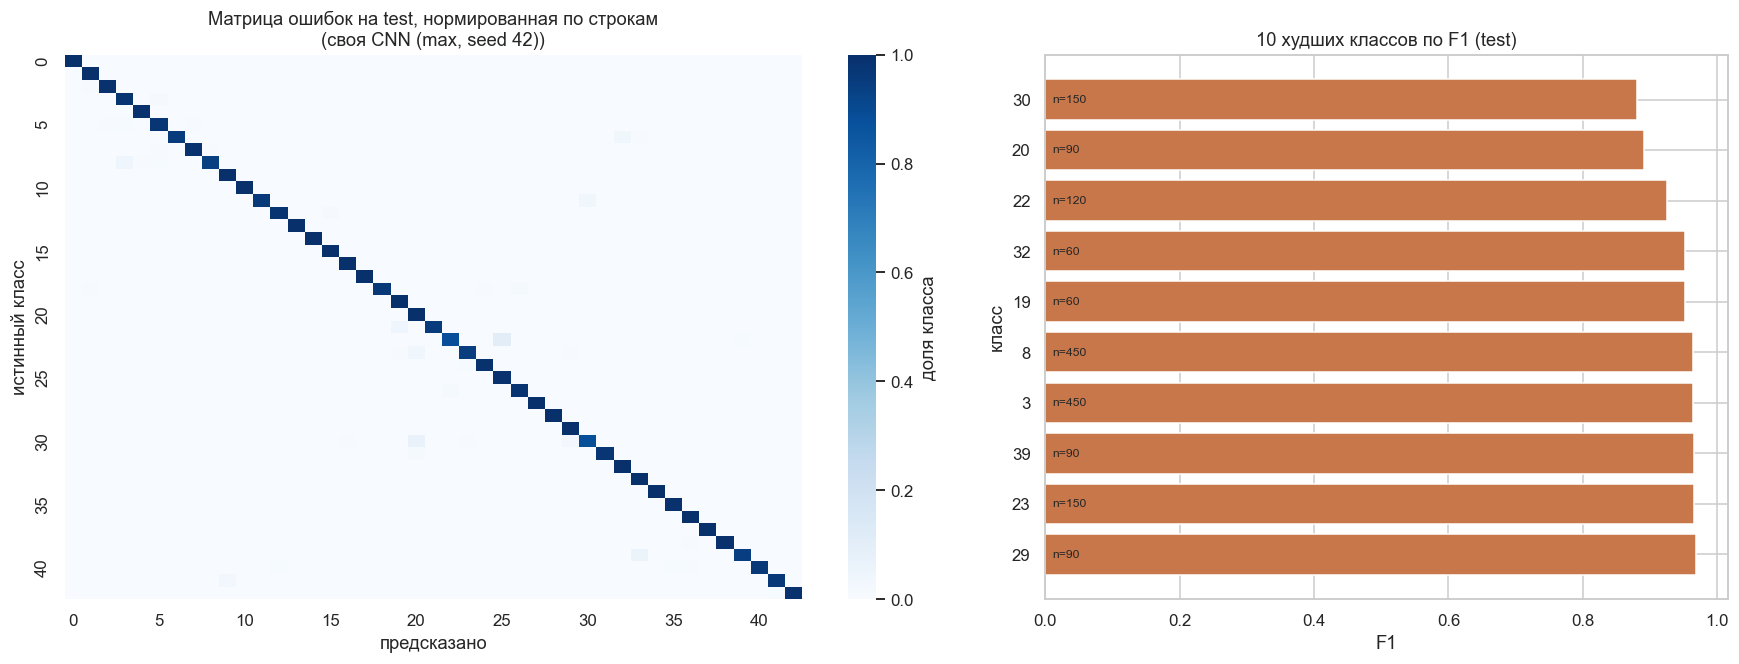

 class  support  recall    f1
    30      150   0.880 0.880
    20       90   1.000 0.891
    22      120   0.883 0.926
    32       60   1.000 0.952
    19       60   1.000 0.952
     8      450   0.940 0.964
     3      450   0.982 0.964
    39       90   0.944 0.966
    23      150   0.947 0.966
    29       90   1.000 0.968


In [17]:
lg = test_logits[best_name]; pred = lg.argmax(1).numpy(); yt = yte.cpu().numpy()
cm = confusion_matrix(yt, pred, labels=range(cfg.n_classes))
per_class = pd.DataFrame({'class': range(cfg.n_classes), 'support': cm.sum(1), 'recall': np.diag(cm) / cm.sum(1).clip(1),
                          'f1': f1_score(yt, pred, average=None, labels=range(cfg.n_classes), zero_division=0)})
fig, ax = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={'width_ratios': [1.35, 1]})
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), ax=ax[0], cmap='Blues', cbar_kws={'label': 'доля класса'}, xticklabels=5, yticklabels=5)
ax[0].set(title=f'Матрица ошибок на test, нормированная по строкам\n({best_name})', xlabel='предсказано', ylabel='истинный класс')
worst = per_class.sort_values('f1').head(10)
ax[1].barh(worst['class'].astype(str), worst['f1'], color='#c8774b'); ax[1].invert_yaxis()
ax[1].set(title='10 худших классов по F1 (test)', xlabel='F1', ylabel='класс')
for i, (s, c) in enumerate(zip(worst['support'], worst['class'])):
    ax[1].text(0.01, i, f'n={s}', va='center', fontsize=8)
plt.tight_layout(); plt.savefig(RES / 'test_confusion.png'); plt.show()
per_class.to_csv(RES / 'test_per_class.csv', index=False)
print(worst.round(3).to_string(index=False))

## 9. Пункт 3: замена свёртки большого ядра стопкой малых (параметры и операции)

**Значения из рейтинга: k1 = 93, k2 = 60, k3 = 0.**

> **Примечание.** Свёртка 93×93 физически неудобна и в AlexNet невозможна: карты признаков AlexNet имеют стороны 55, 27 и 13 (при входе 224), то есть ядро больше самой карты. Ядро 60×60 тоже не помещается. Ядро размера 0 не определено. Тем не менее по заданию расчёт выполнен для этих значений, поэтому он **теоретический** и считается формулами; реальная свёртка 93×93 в сеть не встраивается. Для проверки формул они сверяются с PyTorch на реальных малых ядрах (5, 7, 11) и по числу параметров для 93 и 60.

**Идея замены.** Рецептивное поле стопки из `n` свёрток `3×3` со stride 1 равно `1 + 2n`. Значит, `k×k` (нечётное) заменяется `n = (k−1)/2` слоями `3×3`. Для чётного `k` берётся один слой `2×2` и `(k−2)/2` слоёв `3×3`: `1 + 1 + 2·(k−2)/2 = k`.
- `k = 93` → **46 слоёв 3×3** (RF = 1 + 2·46 = 93);
- `k = 60` → **слой 2×2 + 29 слоёв 3×3** (RF = 1 + 1 + 2·29 = 60);
- `k = 0` → вырожденный случай: свёртки нет, замена не определена.

**Условия расчёта** (как согласовано): вход слоя `C_in=64`, выход `C_out=192` (каналы второй свёртки AlexNet), карта `224×224`, `stride=1`, `padding='same'`, с bias. В стопке первый слой `64→192`, остальные `192→192`. Дополнительно дан сценарий `C_in = C_out = 192`, где отношение параметров равно простому `k² / (9n)`.

**Формулы.**
- Одна свёртка: параметры `k²·C_in·C_out + C_out`, умножения-сложения (MAC) `k²·C_in·C_out·H·W`.
- Стопка из слоёв `k_i`: параметры `Σ (k_i²·c_{i-1}·c_i + c_i)`, MAC `Σ k_i²·c_{i-1}·c_i·H·W`.
- **Число операций в смысле «слоёв»:** глубина растёт с 1 до `n` (больше последовательных свёрток и ReLU, больше промежуточных карт в памяти).

In [18]:
def conv_params(k, cin, cout, bias=True):
    return k * k * cin * cout + (cout if bias else 0)


def conv_macs(k, cin, cout, H, W):
    return k * k * cin * cout * H * W


def stack_spec(k):
    """Размеры ядер стопки с тем же рецептивным полем: нечётное k -> (k-1)/2 слоёв 3×3; чётное -> 2×2 и (k-2)/2 слоёв 3×3."""
    if k <= 0: return []
    if k == 1: return [1]
    return [3] * ((k - 1) // 2) if k % 2 else [2] + [3] * ((k - 2) // 2)


def rf_of_stack(spec):
    return 1 + sum(s - 1 for s in spec)


def stack_cost(spec, cin, cout, H, W):
    params = macs = 0; c_prev = cin
    for s in spec:
        params += conv_params(s, c_prev, cout); macs += conv_macs(s, c_prev, cout, H, W); c_prev = cout
    return params, macs


H = W = 224
rows = []
for label, k, cin, cout in [('k1 = 93', 93, 64, 192), ('k2 = 60', 60, 64, 192), ('k3 = 0', 0, 64, 192),
                            ('справочно k = 11', 11, 64, 192), ('справочно k = 7', 7, 64, 192), ('справочно k = 5', 5, 64, 192),
                            ('k1 = 93, C_in=C_out=192', 93, 192, 192), ('k2 = 60, C_in=C_out=192', 60, 192, 192)]:
    spec = stack_spec(k)
    if not spec:
        rows.append(dict(случай=label, k=k, слоев_в_стопке='—', RF_стопки='—', params_одна='—', params_стопка='—', params_ratio=np.nan, MACs_одна='—', MACs_стопка='—', MACs_ratio=np.nan,
                         примечание='вырожденный случай: свёртки нет'))
        continue
    p1, m1 = conv_params(k, cin, cout), conv_macs(k, cin, cout, H, W)
    ps, ms = stack_cost(spec, cin, cout, H, W)
    assert rf_of_stack(spec) == k
    rows.append(dict(случай=label, k=k, слоев_в_стопке=len(spec), RF_стопки=rf_of_stack(spec), params_одна=p1, params_стопка=ps, params_ratio=p1 / ps, MACs_одна=m1, MACs_стопка=ms, MACs_ratio=m1 / ms,
                     примечание=''))
stack_table = pd.DataFrame(rows)
stack_table.to_csv(RES / 'kernel_stack_cost.csv', index=False)
fmt = stack_table.copy()
for c in ('params_одна', 'params_стопка', 'MACs_одна', 'MACs_стопка'):
    fmt[c] = fmt[c].map(lambda v: f'{v:,.0f}' if isinstance(v, (int, float, np.integer)) else v)
fmt['params_ratio'] = fmt['params_ratio'].map(lambda v: '' if pd.isna(v) else f'{v:.2f}×'); fmt['MACs_ratio'] = fmt['MACs_ratio'].map(lambda v: '' if pd.isna(v) else f'{v:.2f}×')
print(fmt.to_string(index=False))

                 случай  k слоев_в_стопке RF_стопки params_одна params_стопка params_ratio          MACs_одна     MACs_стопка MACs_ratio                      примечание
                k1 = 93 93             46        93 106,279,104    15,049,344        7.06×  5,332,650,688,512 754,672,730,112      7.07×                                
                k2 = 60 60             30        60  44,236,992     9,676,416        4.57×  2,219,625,676,800 485,234,835,456      4.57×                                
                 k3 = 0  0              —         —           —             —                               —               —            вырожденный случай: свёртки нет
       справочно k = 11 11              5        11   1,487,040     1,438,656        1.03×     74,604,085,248  72,137,834,496      1.03×                                
        справочно k = 7  7              3         7     602,304       774,720        0.78×     30,211,571,712  38,843,449,344      0.78×                   

### Проверка формул против PyTorch
- Число параметров считается по реальным модулям `nn.Conv2d` (на `meta`-устройстве, без выделения памяти, поэтому подходят и 93×93, и 46 слоёв).
- MAC проверяются на малых картах через `FlopCounterMode` (FLOPs свёрток = 2·MAC).
- Рецептивное поле стопки проверяется по размеру выхода цепочки `valid`-свёрток: он равен `N − (RF − 1)`.

In [19]:
from torch.utils.flop_counter import FlopCounterMode


def torch_stack(spec, cin, cout, device='meta'):
    layers, c_prev = [], cin
    for s in spec:
        layers.append(nn.Conv2d(c_prev, cout, s, padding=0, device=device)); c_prev = cout
    return nn.Sequential(*layers)


check_rows = []
for k, cin, cout in [(93, 64, 192), (60, 64, 192), (11, 64, 192), (7, 64, 192), (5, 64, 192), (93, 192, 192)]:
    spec = stack_spec(k)
    single = nn.Conv2d(cin, cout, k, device='meta')
    p_single, p_stack = n_params(single), n_params(torch_stack(spec, cin, cout))
    assert p_single == conv_params(k, cin, cout) and p_stack == stack_cost(spec, cin, cout, 1, 1)[0], (k, p_single, p_stack)
    N = 120
    x = torch.zeros(1, 1, N, N)
    y = torch_stack(spec, 1, 1, device='cpu')(x)
    assert y.shape[-1] == N - (k - 1), (k, y.shape)       # рецептивное поле стопки = k
    check_rows.append(dict(k=k, C_in=cin, C_out=cout, слоев=len(spec), params_torch_single=p_single, params_torch_stack=p_stack, RF_ok=True))
print(pd.DataFrame(check_rows).to_string(index=False))

# MAC: формула против FlopCounterMode на малых размерах (valid-свёртки: выход (H-k+1)², поэтому сверяем на 'same' через padding)
for k in (5, 7, 11):
    cin, cout, Hs = 4, 8, 20
    single = nn.Conv2d(cin, cout, k, padding='same', bias=False)
    spec = stack_spec(k)
    stk, c_prev = [], cin
    for s in spec:
        stk.append(nn.Conv2d(c_prev, cout, s, padding=(s - 1) // 2, bias=False)); c_prev = cout
    stk = nn.Sequential(*stk)
    xs = torch.randn(1, cin, Hs, Hs)
    for mod, (pp, mm) in ((single, (conv_params(k, cin, cout, False), conv_macs(k, cin, cout, Hs, Hs))),
                          (stk, (stack_cost(spec, cin, cout, Hs, Hs)[0] - len(spec) * cout, stack_cost(spec, cin, cout, Hs, Hs)[1]))):
        with FlopCounterMode(display=False) as fc:
            mod(xs)
        assert fc.get_total_flops() == 2 * mm, (k, fc.get_total_flops(), 2 * mm)
        assert n_params(mod) == pp
print('MAC и параметры по формулам совпали с PyTorch для k = 5, 7, 11 (одна свёртка и стопка)')

 k  C_in  C_out  слоев  params_torch_single  params_torch_stack  RF_ok
93    64    192     46            106279104            15049344   True
60    64    192     30             44236992             9676416   True
11    64    192      5              1487040             1438656   True
 7    64    192      3               602304              774720   True
 5    64    192      2               307392              442752   True
93   192    192     46            318836928            15270528   True
MAC и параметры по формулам совпали с PyTorch для k = 5, 7, 11 (одна свёртка и стопка)


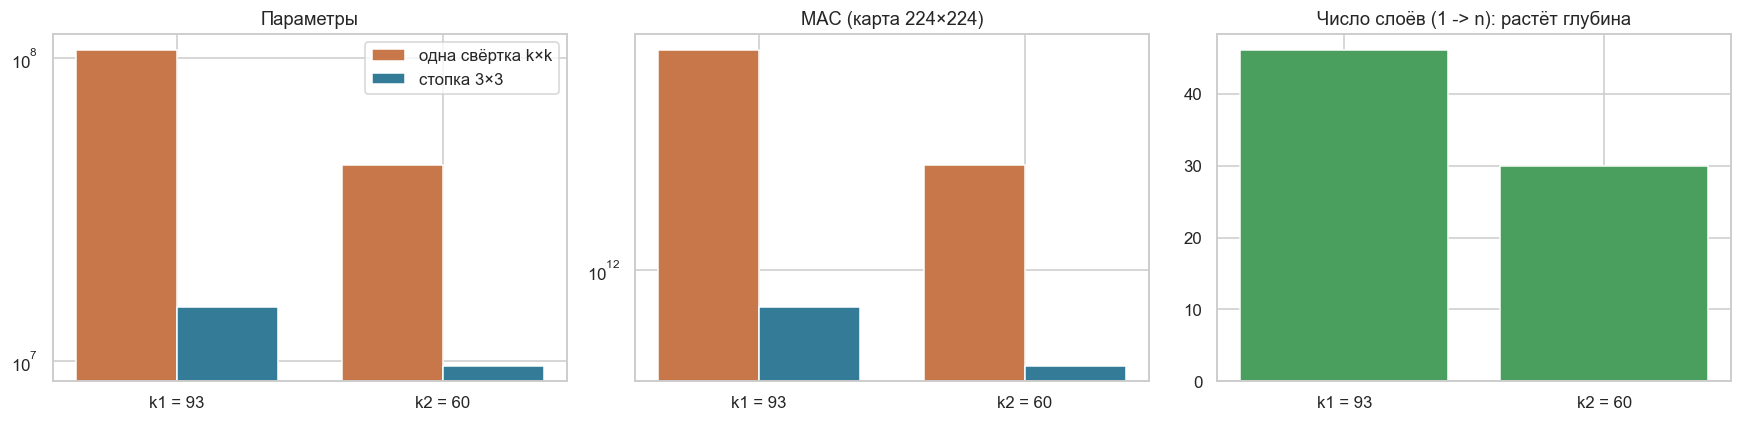

In [20]:
sel = stack_table[stack_table.k.isin([93, 60]) & ~stack_table.случай.str.contains('C_in')]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
xx = np.arange(len(sel)); wd = .38
ax[0].bar(xx - wd / 2, sel.params_одна.astype(float), wd, label='одна свёртка k×k', color='#c8774b'); ax[0].bar(xx + wd / 2, sel.params_стопка.astype(float), wd, label='стопка 3×3', color='#347b98')
ax[0].set_xticks(xx); ax[0].set_xticklabels(sel.случай); ax[0].set(title='Параметры', yscale='log'); ax[0].legend()
ax[1].bar(xx - wd / 2, sel.MACs_одна.astype(float), wd, color='#c8774b'); ax[1].bar(xx + wd / 2, sel.MACs_стопка.astype(float), wd, color='#347b98')
ax[1].set_xticks(xx); ax[1].set_xticklabels(sel.случай); ax[1].set(title='MAC (карта 224×224)', yscale='log')
ax[2].bar(xx, sel.слоев_в_стопке.astype(float), color='#4b9f5e'); ax[2].set_xticks(xx); ax[2].set_xticklabels(sel.случай)
ax[2].set(title='Число слоёв (1 -> n): растёт глубина')
plt.tight_layout(); plt.savefig(RES / 'kernel_stack_cost.png'); plt.show()

### Вывод по пункту 3
- Для одинаковых каналов отношение параметров (и MAC при одинаковой карте) равно `k² / (9n)`, при `n ≈ k/2` это примерно `k/4.5`: чем больше ядро, тем сильнее выигрыш. Для `93` выигрыш примерно в 7 раз, для `60` примерно в 4.5 раза (см. таблицу).
- Для малых ядер при `C_in ≠ C_out` выигрыша может не быть: для `5×5` стопка `3×3 + 3×3` с каналами `64→192→192` содержит **больше** параметров, чем один `5×5` `64→192`, потому что второй слой работает на `192` каналах. Выигрыш определяется соотношением каналов, а не только размером ядра.
- Операции в смысле MAC падают пропорционально параметрам (каждый вес используется `H·W` раз), а **число последовательных операций** (слоёв, нелинейностей) и объём промежуточных активаций растут: вместо одной свёртки `n` свёрток и `n−1` лишних карт `192×224×224` в памяти. Побочный плюс: между слоями стопки добавляются ReLU, и функция становится более выразительной.
- Практический предел: ядро 93 не помещается в карты AlexNet, 46-слойная стопка без skip-связей очень трудно обучается. Эти ядра остаются теоретическим упражнением, как и оговорено в примечании.

## 10. Пункт 4: эквивариантность свёрточного преобразования

**Определения.** Для сигнала `x: ℤ² → ℝ` и ядра `w` (в сетях «свёртка» — это кросс-корреляция):
$$(x \star w)[i] = \sum_{u} w[u]\,x[i+u],$$
оператор сдвига на вектор `s`: $(T_s x)[i] = x[i - s]$. Преобразование `f` **эквивариантно к сдвигу**, если $f(T_s x) = T_s f(x)$ для любого `s`.

**Теорема.** Свёртка эквивариантна к сдвигу: $(T_s x) \star w = T_s (x \star w)$.

**Доказательство.**
$$((T_s x)\star w)[i] = \sum_u w[u]\,(T_s x)[i+u] = \sum_u w[u]\,x[i+u-s].$$
Правая часть: $(T_s(x\star w))[i] = (x\star w)[i-s] = \sum_u w[u]\,x[(i-s)+u]$. Суммы совпадают для всех `i`, что и требовалось. $\blacksquare$

**Многоканальный случай.** $y_o[i] = b_o + \sum_c \sum_u w_{o,c}[u]\,x_c[i+u]$ — линейная комбинация сдвигов одних и тех же каналов с коэффициентами, не зависящими от `i`; тот же вывод, суммирование по `c` ничего не меняет. Смещение `b_o` — константа, она не зависит от позиции и тоже коммутирует со сдвигом.

**Следствия.**
1. Композиция эквивариантных преобразований эквивариантна: стопка свёрток, а также поэлементные ReLU/BatchNorm (в режиме `eval`) не ломают эквивариантность.
2. **Stride `s`:** сдвиг на `m·s` входа даёт сдвиг на `m` выхода: $(x\star_s w)[j] = \sum_u w[u]\,x[sj+u]$, значит $((T_{ms}x)\star_s w)[j] = (x\star_s w)[j-m]$. К сдвигу, не кратному `s`, эквивариантности нет; то же у `MaxPool 2×2/2`.
3. **Границы.** На конечном изображении равенство точное только при циклическом дополнении (`circular padding`); при нулевом дополнении оно выполняется для позиций, чьё рецептивное поле не задевает границу.
4. Эквивариантность — не инвариантность: классификатору нужна инвариантность, которую даёт глобальная агрегация (Flatten/Dropout/линейные слои приближённо, GAP — точно).

**Численная проверка** ниже.

In [21]:
torch.manual_seed(0)
dt = torch.float64
conv = nn.Conv2d(3, 5, 5, padding=0, dtype=dt).eval()
x = torch.randn(1, 3, 40, 40, dtype=dt)


def circ_conv(x, conv, stride=1):
    p = conv.kernel_size[0] // 2
    return F.conv2d(F.pad(x, (p, p, p, p), mode='circular'), conv.weight, conv.bias, stride=stride)


def zero_conv(x, conv, stride=1):
    p = conv.kernel_size[0] // 2
    return F.conv2d(F.pad(x, (p, p, p, p)), conv.weight, conv.bias, stride=stride)


def shift_circ(t, sy, sx):
    return torch.roll(t, shifts=(sy, sx), dims=(2, 3))


def shift_zero(t, sy, sx):
    out = torch.zeros_like(t); H_, W_ = t.shape[2:]
    out[:, :, max(sy, 0):H_ + min(sy, 0), max(sx, 0):W_ + min(sx, 0)] = t[:, :, max(-sy, 0):H_ + min(-sy, 0), max(-sx, 0):W_ + min(-sx, 0)]
    return out


def maxdiff(a, b, margin=0):
    if margin: a, b = a[..., margin:-margin, margin:-margin], b[..., margin:-margin, margin:-margin]
    return (a - b).abs().max().item()


sy, sx = 3, 5
eq_rows = []
# 1. circular padding, stride 1: точное равенство
eq_rows.append(('conv 5×5, circular padding, сдвиг (3,5)', maxdiff(circ_conv(shift_circ(x, sy, sx), conv), shift_circ(circ_conv(x, conv), sy, sx))))
# 2. zero padding: на границе равенство нарушается, внутри — выполняется
a, b = zero_conv(shift_zero(x, sy, sx), conv), shift_zero(zero_conv(x, conv), sy, sx)
eq_rows.append(('conv 5×5, zero padding, вся карта', maxdiff(a, b)))
eq_rows.append(('conv 5×5, zero padding, внутренняя область (отступ 2+max|сдвига|)', maxdiff(a, b, margin=2 + max(sy, sx))))
# 3. stride 2: кратный шагу сдвиг эквивариантен (выход сдвигается на 1), некратный — нет
y0 = circ_conv(x, conv, stride=2)
eq_rows.append(('conv, stride 2, circular, сдвиг входа 2 -> выхода 1', maxdiff(circ_conv(shift_circ(x, 2, 2), conv, 2), shift_circ(y0, 1, 1))))
eq_rows.append(('conv, stride 2, circular, сдвиг входа 1 (не кратен шагу)', maxdiff(circ_conv(shift_circ(x, 1, 1), conv, 2), shift_circ(y0, 0, 0))))
# 4. MaxPool 2×2: то же
pool = nn.MaxPool2d(2)
eq_rows.append(('MaxPool 2×2/2, сдвиг входа 2 -> выхода 1', maxdiff(pool(shift_circ(x, 2, 2)), shift_circ(pool(x), 1, 1))))
eq_rows.append(('MaxPool 2×2/2, сдвиг входа 1 (не кратен шагу)', maxdiff(pool(shift_circ(x, 1, 1)), pool(x))))
# 5. обученный первый блок своей CNN (Conv-BN-ReLU, eval): внутренняя область, zero padding
import copy
blk = copy.deepcopy(cnn_runs[f'cnn_{best_pool}_s42'][1].features[:3]).cpu().double().eval()
xi = (Xte[:1].cpu().double() / 255)
sh = lambda t: shift_zero(t, 4, 7)
eq_rows.append(('обученный блок Conv3×3+BN+ReLU, внутренняя область (отступ 12)', maxdiff(blk(sh(xi)), sh(blk(xi)), margin=12)))
eq_table = pd.DataFrame(eq_rows, columns=['проверка', 'max |f(T x) − T f(x)|'])
eq_table.to_csv(RES / 'equivariance_checks.csv', index=False)
print(eq_table.to_string(index=False, float_format=lambda v: f'{v:.3e}'))
assert all(eq_table.iloc[i, 1] < 1e-10 for i in (0, 2, 3, 5, 7))
assert eq_table.iloc[1, 1] > 1e-3 and eq_table.iloc[4, 1] > 1e-3 and eq_table.iloc[6, 1] > 1e-3

                                                         проверка  max |f(T x) − T f(x)|
                          conv 5×5, circular padding, сдвиг (3,5)              0.000e+00
                                conv 5×5, zero padding, вся карта              1.206e+00
conv 5×5, zero padding, внутренняя область (отступ 2+max|сдвига|)              0.000e+00
              conv, stride 2, circular, сдвиг входа 2 -> выхода 1              0.000e+00
         conv, stride 2, circular, сдвиг входа 1 (не кратен шагу)              3.531e+00
                         MaxPool 2×2/2, сдвиг входа 2 -> выхода 1              0.000e+00
                    MaxPool 2×2/2, сдвиг входа 1 (не кратен шагу)              2.878e+00
   обученный блок Conv3×3+BN+ReLU, внутренняя область (отступ 12)              0.000e+00


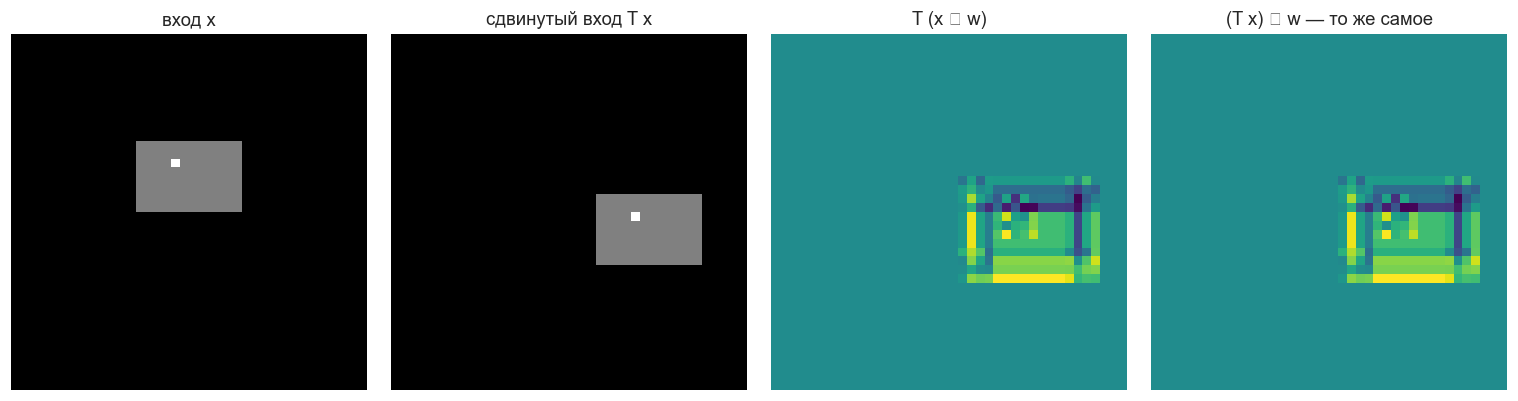

In [22]:
img = Xte[0].float().cpu() / 255
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
w0 = conv.weight.detach()
x1 = torch.zeros(1, 3, 40, 40, dtype=dt); x1[0, :, 12:20, 14:26] = 1.; x1[0, :, 14, 18] = 2.
yA, yB = circ_conv(x1, conv)[0, 0].detach().numpy(), circ_conv(shift_circ(x1, 6, 9), conv)[0, 0].detach().numpy()
ax[0].imshow(x1[0, 0], cmap='gray'); ax[0].set_title('вход x')
ax[1].imshow(shift_circ(x1, 6, 9)[0, 0], cmap='gray'); ax[1].set_title('сдвинутый вход T x')
ax[2].imshow(np.roll(yA, (6, 9), (0, 1)), cmap='viridis'); ax[2].set_title('T (x ⋆ w)')
ax[3].imshow(yB, cmap='viridis'); ax[3].set_title('(T x) ⋆ w — то же самое')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'equivariance.png'); plt.show()

**Вывод по пункту 4.** Теорема доказана аналитически; численно при циклическом дополнении ошибка равна нулю или имеет порядок `1e-16` (float64), при нулевом дополнении расхождение появляется только у границы, при stride 2 и пулинге равенство выполняется лишь для сдвигов, кратных шагу. Поэтому пулинги и stride дают лишь *приближённую* инвариантность к малым сдвигам.

## 11. Пункт 5: деконволюция (транспонированная свёртка)

**Что это.** Свёртка — линейное отображение `y = C x`, где `C` — «матрица свёртки» (теплицева/блочно-теплицева). **Транспонированная свёртка** (часто неточно называемая деконволюцией) — это `x' = Cᵀ y`: она переводит карту `y` меньшего размера в карту размера исходного входа, но не обращает свёртку (не восстанавливает `x`), а лишь возвращает *форму* и «распределяет» значения по окну ядра.

**Алгоритм (scatter).** Каждый пиксель входа `x[c_in, i, j]` добавляет в выход окно, равное значению пикселя, умноженному на ядро:
$$y[c_{out},\ s i + u - p,\ s j + v - p] \mathrel{+}= \sum_{c_{in}} x[c_{in}, i, j]\;W[c_{in}, c_{out}, u, v].$$
Размер выхода: $H_{out} = (H_{in}-1)\,s - 2p + (k-1) + \text{output\_padding} + 1$. Буфер размера `(H_in−1)·s + k + output_padding` заполняется суммированием, затем отрезается `p` пикселей с каждого края.

Ниже функция написана вручную (без `nn.ConvTranspose2d`), проверена против PyTorch на разных `k, s, p, output_padding`, и независимо — через матричное определение `Cᵀ`.

In [23]:
def conv_transpose2d_manual(x, w, stride=1, padding=0, output_padding=0, bias=None):
    """Транспонированная свёртка вручную. x: (B, C_in, H, W); w: (C_in, C_out, k, k) — как в nn.ConvTranspose2d."""
    B, Ci, Hi, Wi = x.shape; _, Co, kh, kw = w.shape
    Hb = (Hi - 1) * stride + kh + output_padding
    Wb = (Wi - 1) * stride + kw + output_padding
    out = torch.zeros(B, Co, Hb, Wb, dtype=x.dtype, device=x.device)
    for u in range(kh):
        for v in range(kw):
            z = torch.einsum('bihw,io->bohw', x, w[:, :, u, v])               # вклад каждого пикселя по смещению ядра (u, v)
            out[:, :, u:u + stride * (Hi - 1) + 1:stride, v:v + stride * (Wi - 1) + 1:stride] += z
    out = out[:, :, padding:Hb - padding, padding:Wb - padding]
    return out + bias.view(1, -1, 1, 1) if bias is not None else out


torch.manual_seed(0)
cfgs = [(3, 1, 0, 0), (3, 1, 1, 0), (3, 2, 1, 0), (3, 2, 1, 1), (4, 2, 1, 0), (5, 3, 2, 1), (11, 4, 2, 1), (2, 2, 0, 0)]
rows = []
for k, s, p, op in cfgs:
    xx_ = torch.randn(2, 6, 9, 11, dtype=torch.float64); ww = torch.randn(6, 4, k, k, dtype=torch.float64); bb = torch.randn(4, dtype=torch.float64)
    mine = conv_transpose2d_manual(xx_, ww, s, p, op, bb)
    ref_ = F.conv_transpose2d(xx_, ww, bb, stride=s, padding=p, output_padding=op)
    assert mine.shape == ref_.shape
    rows.append(dict(k=k, stride=s, padding=p, output_padding=op, выход=tuple(mine.shape[2:]), max_ошибка=(mine - ref_).abs().max().item()))
dec_table = pd.DataFrame(rows)
assert dec_table.max_ошибка.max() < 1e-12
print(dec_table.to_string(index=False, float_format=lambda v: f'{v:.1e}'))


def conv_matrix(w, H_, W_, stride, padding):
    """Матрица C слоя Conv2d(1->1) для входа H_×W_: каждый столбец — отклик на базисный пиксель."""
    cols = []
    for idx in range(H_ * W_):
        e = torch.zeros(1, 1, H_, W_, dtype=w.dtype); e.view(-1)[idx] = 1
        cols.append(F.conv2d(e, w, stride=stride, padding=padding).reshape(-1))
    return torch.stack(cols, 1)


w1 = torch.randn(1, 1, 3, 3, dtype=torch.float64)
C = conv_matrix(w1, 8, 8, 2, 1)                       # 8×8 -> 4×4: матрица 16×64
yv = torch.randn(1, 1, 4, 4, dtype=torch.float64)
via_matrix = (C.T @ yv.reshape(-1)).reshape(1, 1, 8, 8)
via_manual = conv_transpose2d_manual(yv, w1.transpose(0, 1), stride=2, padding=1, output_padding=1)
print('C:', tuple(C.shape), '| ‖Cᵀy − manual(y)‖∞ =', f'{(via_matrix - via_manual).abs().max().item():.1e}')
assert (via_matrix - via_manual).abs().max() < 1e-12
print('Cᵀ C ≠ I (деконволюция не обращает свёртку): ‖CᵀC − I‖ =', f'{(C.T @ C - torch.eye(64, dtype=torch.float64)).norm().item():.2f}')

 k  stride  padding  output_padding    выход  max_ошибка
 3       1        0               0 (11, 13)     5.3e-15
 3       1        1               0  (9, 11)     5.3e-15
 3       2        1               0 (17, 21)     3.6e-15
 3       2        1               1 (18, 22)     7.1e-15
 4       2        1               0 (18, 22)     3.6e-15
 5       3        2               1 (26, 32)     3.6e-15
11       4        2               1 (40, 48)     7.1e-15
 2       2        0               0 (18, 22)     1.8e-15
C: (16, 64) | ‖Cᵀy − manual(y)‖∞ = 2.2e-16
Cᵀ C ≠ I (деконволюция не обращает свёртку): ‖CᵀC − I‖ = 43.77


### Применение: карты признаков и обратная проекция
1. **Карты признаков** обученной CNN: по четырём блокам видно, как падает пространственное разрешение (`64 → 32 → 16 → 8 → 4`) и растёт абстрактность.
2. **Обратная проекция (упрощённая «деконволюция» по Зейлеру и Фергусу):** берём первый свёрточный слой, оставляем отклик одного канала (остальные обнуляем) и переводим его в пространство входа своей `conv_transpose2d_manual` с теми же весами. Это показывает, какой паттерн изображения возбуждает канал (BatchNorm, ReLU и пулинг при проекции не учитываются, так что это иллюстрация, а не точная реконструкция).
3. **Фильтры `11×11` первого слоя fine-tuned AlexNet**, проекция её первого слоя тем же способом (`stride 4`, `output_padding 1`).

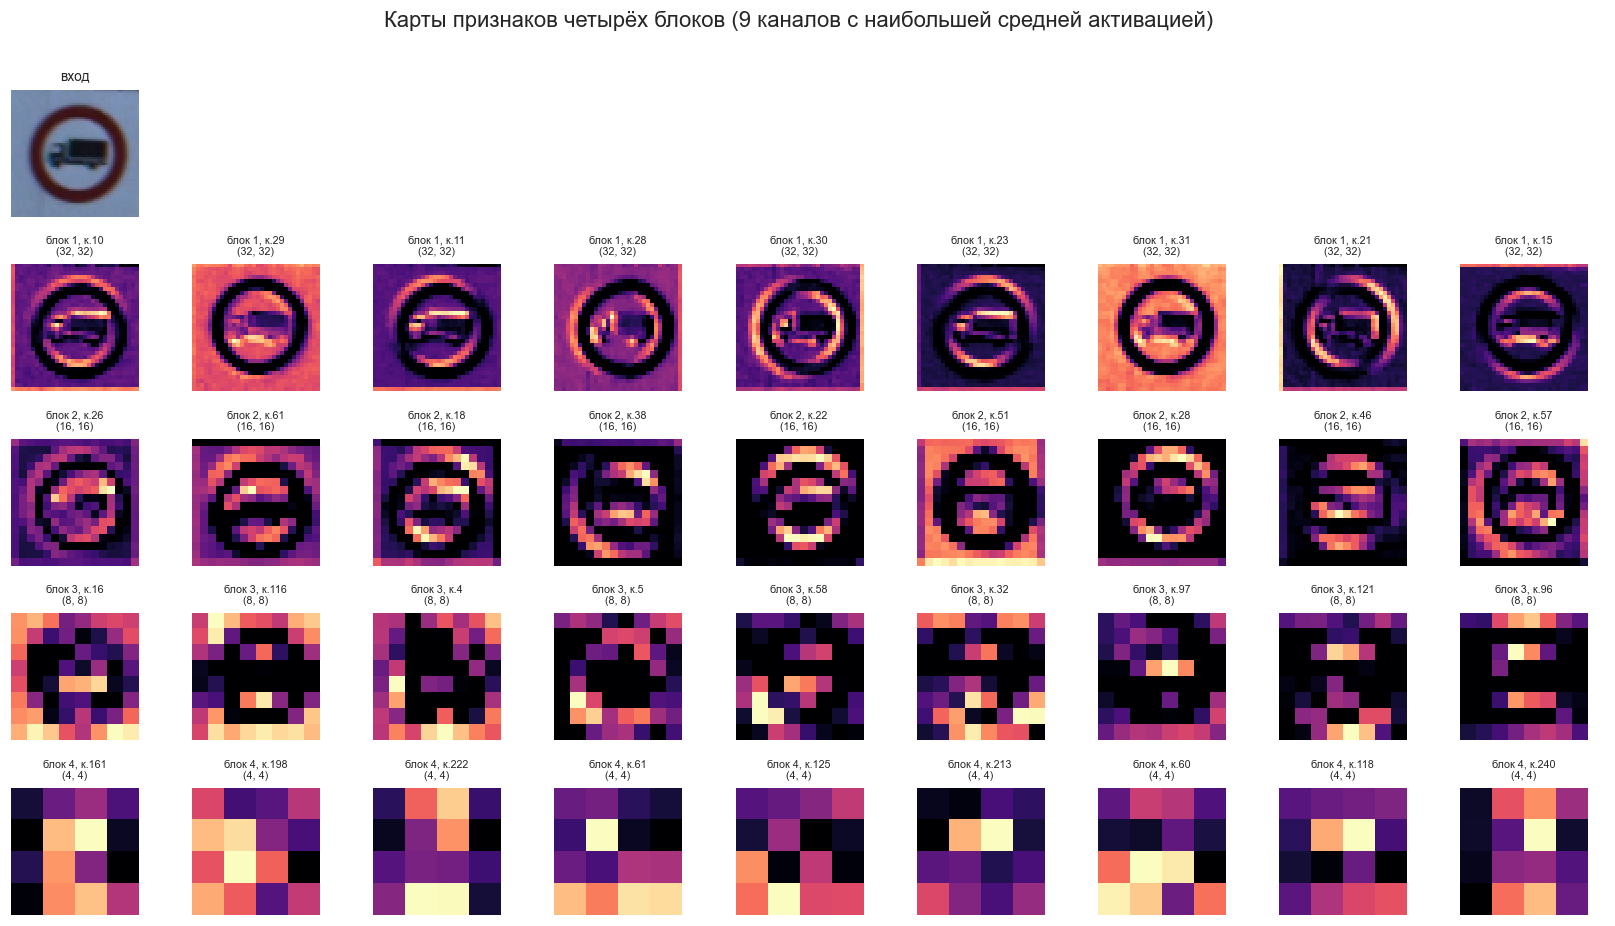

In [24]:
cnn_best = cnn_runs[f'cnn_{best_pool}_s42'][1].to(device).eval()
sample_idx = int(np.where(test_y == test_y[0])[0][0]); sample = Xte[sample_idx:sample_idx + 1].float() / 255
with torch.no_grad():
    t = cnn_best.norm(sample); acts = []
    for b in range(4):
        t = cnn_best.features[4 * b:4 * b + 4](t); acts.append(t[0].cpu())
fig, axes = plt.subplots(5, 9, figsize=(15, 8.4))
axes[0, 0].imshow(sample[0].permute(1, 2, 0).cpu()); axes[0, 0].set_title('вход', fontsize=9)
for j in range(1, 9): axes[0, j].axis('off')
axes[0, 0].axis('off')
for b, a in enumerate(acts):
    top = a.mean((1, 2)).argsort(descending=True)[:9]
    for j, c in enumerate(top):
        axes[b + 1, j].imshow(a[c], cmap='magma'); axes[b + 1, j].axis('off'); axes[b + 1, j].set_title(f'блок {b + 1}, к.{int(c)}\n{tuple(a.shape[1:])}', fontsize=7)
plt.suptitle('Карты признаков четырёх блоков (9 каналов с наибольшей средней активацией)', y=1.0)
plt.tight_layout(); plt.savefig(RES / 'feature_maps.png', bbox_inches='tight'); plt.show()

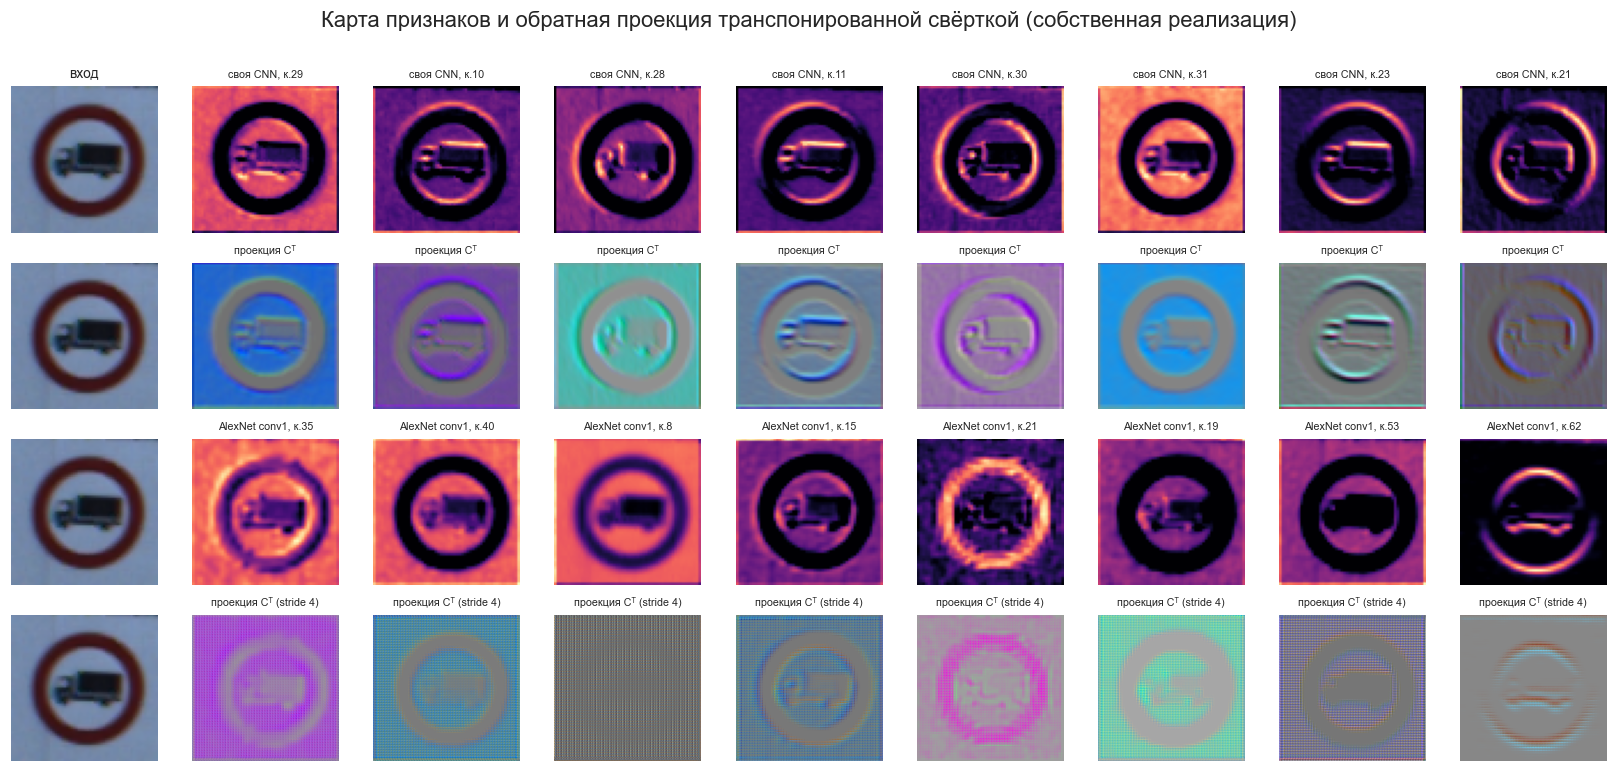

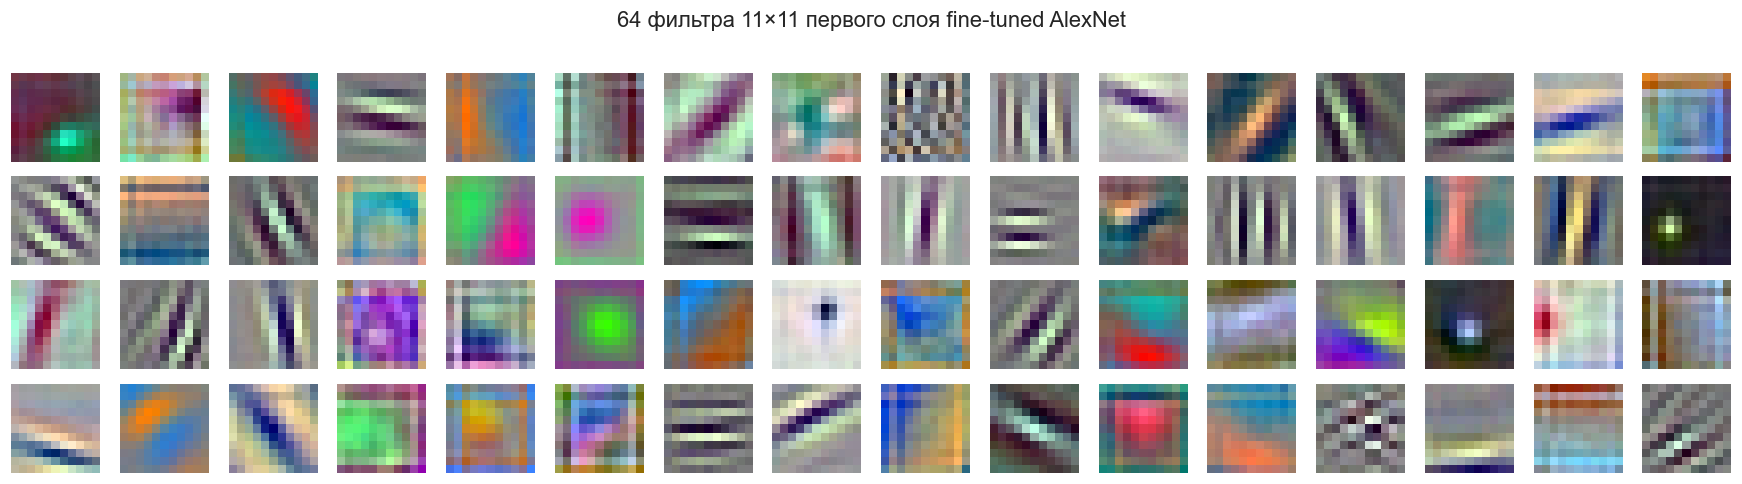

In [25]:
conv1 = cnn_best.features[0]
with torch.no_grad():
    xn = cnn_best.norm(sample)
    y1 = F.relu(cnn_best.features[1](conv1(xn)))          # после conv + BN + ReLU, 32×64×64
    top = y1[0].mean((1, 2)).argsort(descending=True)[:8]
    proj = []
    for c in top:
        only = torch.zeros_like(y1); only[:, c] = y1[:, c]
        # conv1 без bias (BN) : Conv2d(3 -> w, 3×3, pad 1) => транспонированная с теми же весами (C_in=w, C_out=3)
        proj.append(conv_transpose2d_manual(only, conv1.weight, stride=1, padding=1)[0].cpu())
alex_conv1 = alex_ft.net.features[0]
with torch.no_grad():
    xa = alex_ft.norm(alex_ft.resize(sample)); ya = F.relu(alex_conv1(xa))      # 64×55×55 при входе 224
    topa = ya[0].mean((1, 2)).argsort(descending=True)[:8]
    proja = []
    for c in topa:
        only = torch.zeros_like(ya); only[:, c] = ya[:, c]
        proja.append(conv_transpose2d_manual(only, alex_conv1.weight, stride=4, padding=2, output_padding=1)[0].cpu())
norm01 = lambda t: ((t - t.min()) / (t.max() - t.min() + 1e-9)).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(4, 9, figsize=(15, 7))
for r in range(4):
    axes[r, 0].imshow(sample[0].permute(1, 2, 0).cpu()); axes[r, 0].axis('off')
axes[0, 0].set_title('вход', fontsize=9)
for j in range(8):
    axes[0, j + 1].imshow(y1[0, top[j]].cpu(), cmap='magma'); axes[0, j + 1].set_title(f'своя CNN, к.{int(top[j])}', fontsize=7)
    axes[1, j + 1].imshow(norm01(proj[j])); axes[1, j + 1].set_title('проекция Cᵀ', fontsize=7)
    axes[2, j + 1].imshow(ya[0, topa[j]].cpu(), cmap='magma'); axes[2, j + 1].set_title(f'AlexNet conv1, к.{int(topa[j])}', fontsize=7)
    axes[3, j + 1].imshow(norm01(proja[j])); axes[3, j + 1].set_title('проекция Cᵀ (stride 4)', fontsize=7)
for a in axes.ravel(): a.axis('off')
plt.suptitle('Карта признаков и обратная проекция транспонированной свёрткой (собственная реализация)', y=1.0)
plt.tight_layout(); plt.savefig(RES / 'deconv_projection.png', bbox_inches='tight'); plt.show()

wf = alex_conv1.weight.detach().cpu()
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for i, a in enumerate(axes.ravel()):
    f_ = wf[i]; a.imshow(((f_ - f_.min()) / (f_.max() - f_.min() + 1e-9)).permute(1, 2, 0).numpy()); a.axis('off')
plt.suptitle('64 фильтра 11×11 первого слоя fine-tuned AlexNet', y=1.0); plt.tight_layout(); plt.savefig(RES / 'alexnet_conv1_filters.png', bbox_inches='tight'); plt.show()

## 12. Пункт 6: формулы и их объяснение

Для слоя с ядром `k`, шагом `s`, дополнением `p` и расширением (dilation) `d`, вход `n×n`.

**Формула 1. Размер карты признаков после свёртки.**
$$n_{out} = \left\lfloor \frac{n + 2p - d\,(k-1) - 1}{s} \right\rfloor + 1.$$
*Откуда:* с учётом дополнения вход имеет длину `n + 2p`; эффективный размер ядра `d(k−1)+1`; первое окно занимает позиции `0..d(k−1)`; остальные окна сдвинуты на `s`, поэтому число позиций — это число шагов `⌊(n+2p−d(k−1)−1)/s⌋` плюс первое окно. Для пулинга та же формула.

**Формула 2. Padding, сохраняющий размер.** При `s = 1`: `n_out = n + 2p − d(k−1)`, и `n_out = n` при
$$p = \frac{d\,(k-1)}{2}.$$
Для `d=1`: `p = (k−1)/2` (`k = 3 → p = 1`, `k = 5 → p = 2`); для чётного `k` целого `p` нет (нужен асимметричный padding, поэтому в сетях ядра нечётные).

**Формула 3. Рецептивное поле.** Слои `l = 1..L` с `(k_l, s_l, d_l)`; `j_0 = 1` — «шаг» признаков во входных пикселях, `r_0 = 1`:
$$r_l = r_{l-1} + d_l\,(k_l-1)\,j_{l-1},\qquad j_l = j_{l-1}\,s_l.$$
*Смысл:* слой с ядром `k` добавляет `k−1` соседних единиц предыдущей карты, а одна единица предыдущей карты равна `j_{l-1}` входных пикселей.

**Формула 4. Stride для сжатия изображения в `n` раз.** При `p = (k − s)/2` (`k ≥ s`, `k − s` чётно):
$$n_{out} = \left\lfloor \frac{n_{in} + (k-s) - k}{s} \right\rfloor + 1 = \left\lfloor \frac{n_{in}}{s} \right\rfloor,$$
значит для сжатия в `m` раз берём **`s = m`**, `k = m` или `k = m + 2t`, `p = t`. Пулинг `kernel = stride = m`, `p = 0` даёт то же `⌊n_in/m⌋`.

Ниже все четыре формулы проверены против PyTorch (по сетке параметров) и применены к моделям лабы.

In [26]:
# Формула 1 (и пулинг): сетка параметров
cnt = 0
for n_ in range(5, 40, 3):
    for k in range(1, 8):
        for s in (1, 2, 3):
            for p in range(0, 4):
                for d in (1, 2):
                    eff = d * (k - 1) + 1
                    if n_ + 2 * p < eff or p > eff // 2 + 3: continue
                    f1 = (n_ + 2 * p - d * (k - 1) - 1) // s + 1
                    got = F.conv2d(torch.zeros(1, 1, n_, n_), torch.zeros(1, 1, k, k), stride=s, padding=p, dilation=d).shape[-1]
                    assert f1 == got, (n_, k, s, p, d, f1, got); cnt += 1
                    if d == 1 and p <= k // 2:
                        assert f1 == F.max_pool2d(torch.zeros(1, 1, n_, n_), k, s, p).shape[-1]
print(f'Формула 1: совпала с nn.Conv2d / MaxPool2d на {cnt} наборах параметров')

# Формула 2: padding «same»
cnt = 0
for n_ in (8, 17, 33):
    for k in (1, 3, 5, 7, 9):
        for d in (1, 2, 3):
            p = d * (k - 1) // 2
            assert F.conv2d(torch.zeros(1, 1, n_, n_), torch.zeros(1, 1, k, k), padding=p, dilation=d).shape[-1] == n_; cnt += 1
print(f'Формула 2: размер сохраняется на {cnt} наборах (нечётные k, dilation 1–3)')

# Формула 4: сжатие в m раз
cnt = 0
for n_ in (32, 64, 100, 224):
    for m in (2, 3, 4, 8):
        for t in range(0, 4):
            k, p = m + 2 * t, t
            out = F.conv2d(torch.zeros(1, 1, n_, n_), torch.zeros(1, 1, k, k), stride=m, padding=p).shape[-1]
            assert out == n_ // m, (n_, m, k, p, out); cnt += 1
        assert F.max_pool2d(torch.zeros(1, 1, n_, n_), m, m).shape[-1] == n_ // m
print(f'Формула 4: s = m даёт ⌊n/m⌋ на {cnt} наборах (свёртка с p=(k−s)/2 и пулинг)')

# Формула 3: рецептивное поле — формула и эксперимент
def rf_formula(layers):
    r, j = 1, 1
    for k, s, d in layers:
        r += d * (k - 1) * j; j *= s
    return r, j


def rf_empirical(layers, n_=600):
    """Линейный аналог: свёртки из единиц; размер носителя градиента центрального выхода по входу = рецептивное поле."""
    mods = [nn.Conv2d(1, 1, k, stride=s, padding=(d * (k - 1)) // 2, dilation=d, bias=False) for k, s, d in layers]
    for m in mods: nn.init.constant_(m.weight, 1.)
    net = nn.Sequential(*mods)
    x = torch.zeros(1, 1, n_, n_, requires_grad=True)
    y = net(x); c = y.shape[-1] // 2
    y[0, 0, c, c].backward()
    g = x.grad[0, 0] != 0
    nz = g[g.sum(1).argmax()].nonzero().flatten()
    return int(nz.max() - nz.min() + 1)


alex_layers = [(11, 4, 1), (3, 2, 1), (5, 1, 1), (3, 2, 1), (3, 1, 1), (3, 1, 1), (3, 1, 1), (3, 2, 1)]       # AlexNet.features, пулинги как окна
cnn_layers = [(3, 1, 1), (2, 2, 1)] * 4                                                                          # своя CNN: 4 × (Conv3×3, Pool2×2)
rf_rows = []
for nm, layers in (('AlexNet.features', alex_layers), ('своя CNN', cnn_layers), ('стопка 46×(3×3)', [(3, 1, 1)] * 46), ('стопка 2×2 + 29×(3×3)', [(2, 1, 1)] + [(3, 1, 1)] * 29),
                   ('conv 3×3, dilation 2, ×3', [(3, 1, 2)] * 3)):
    r_f, j_f = rf_formula(layers)
    r_e = rf_empirical(layers, 700)
    rf_rows.append(dict(сеть=nm, слоёв=len(layers), RF_формула=r_f, RF_эксперимент=r_e, шаг_признаков_j=j_f))
    assert r_f == r_e, (nm, r_f, r_e)
rf_table = pd.DataFrame(rf_rows); rf_table.to_csv(RES / 'receptive_field.csv', index=False)
print(rf_table.to_string(index=False))
print('\nПримеры применения формул:')
print(' AlexNet conv1 на входе 64: n_out = ⌊(64 + 2·2 − 11)/4⌋ + 1 =', (64 + 4 - 11) // 4 + 1, '(проверено выше по размерам features)')
print(' сжатие 64 -> 8 (в 8 раз): s = 8, например k = 8, p = 0 или k = 10, p = 1')

Формула 1: совпала с nn.Conv2d / MaxPool2d на 1959 наборах параметров
Формула 2: размер сохраняется на 45 наборах (нечётные k, dilation 1–3)
Формула 4: s = m даёт ⌊n/m⌋ на 64 наборах (свёртка с p=(k−s)/2 и пулинг)


                    сеть  слоёв  RF_формула  RF_эксперимент  шаг_признаков_j
        AlexNet.features      8         195             195               32
                своя CNN      8          46              46               16
         стопка 46×(3×3)     46          93              93                1
   стопка 2×2 + 29×(3×3)     30          60              60                1
conv 3×3, dilation 2, ×3      3          13              13                1

Примеры применения формул:
 AlexNet conv1 на входе 64: n_out = ⌊(64 + 2·2 − 11)/4⌋ + 1 = 15 (проверено выше по размерам features)
 сжатие 64 -> 8 (в 8 раз): s = 8, например k = 8, p = 0 или k = 10, p = 1


**Что отвечать на защите по формулам.**
1. *Размер карты:* число позиций окна по длине с учётом дополнения и dilation. Размер падает при росте `k`, `d`, `s` и растёт с `p`.
2. *Padding:* чтобы центр окна проходил по всем `n` позициям, окно должно «выступать» за границу на `d(k−1)/2` пикселей с каждой стороны.
3. *Рецептивное поле:* растёт линейно по `k` и **мультипликативно через stride**: после слоя с шагом `s` каждая единица карты стоит в `s` раз дальше; AlexNet.features даёт RF 195 пикселей, что заметно больше стороны нашей картинки 64×64: конечные нейроны «видят» весь вход (остальное — нулевой padding).
4. *Сжатие:* чтобы сжать карту в `m` раз, достаточно `stride = m` (окно не должно быть меньше шага, иначе будут «дыры», поэтому `k ≥ s`).

## 13. Выводы

In [27]:
b_pool = pool_summary
tt = test_table.set_index('модель')
fit_idx = fit_table.set_index('режим')
over, fix, under = fit_idx.loc['переобучение w=48'], fit_idx.loc['исправлено w=32'], fit_idx.loc['недообучение w=1']
vt = val_table.set_index('модель')
alex_names = ['AlexNet с нуля', 'AlexNet fine-tuning']
lines = []
lines.append('### Выводы по фактическим результатам')
lines.append(f'- Данные: GTSRB, {len(tr_idx)} train / {len(val_idx)} validation (группы по трекам, утечки нет) / {len(yte)} test. Вход своих моделей {cfg.img_size}×{cfg.img_size}, AlexNet — {cfg.alex_size}×{cfg.alex_size} (увеличение внутри модели). Константный прогноз: validation macro-F1 **{const_f1:.3f}**.')
lines.append(f'- MLP: validation macro-F1 **{vt.loc["MLP", "val_f1"]:.3f}**; своя CNN ({best_pool}) **{vt.iloc[2]["val_f1"]:.3f}** при {int(vt.iloc[2]["параметров"]):,} параметров; AlexNet с нуля **{vt.loc["AlexNet с нуля", "val_f1"]:.3f}**; AlexNet fine-tuning **{vt.loc["AlexNet fine-tuning", "val_f1"]:.3f}**.')
lines.append(f'- Пулинги (3 seed): max **{b_pool.loc["max", "val_f1_mean"]:.4f} ± {b_pool.loc["max", "val_f1_std"]:.4f}**, avg **{b_pool.loc["avg", "val_f1_mean"]:.4f} ± {b_pool.loc["avg", "val_f1_std"]:.4f}**; выбран {best_pool}. Разница средних {b_pool.val_f1_mean.max() - b_pool.val_f1_mean.min():.4f} ' + ('больше удвоенного наибольшего разброса, преимущество согласуется на трёх seed.' if b_pool.val_f1_mean.max() - b_pool.val_f1_mean.min() > 2 * b_pool.val_f1_std.max() else 'сопоставима с разбросом seed и не доказывает преимущество.'))
lines.append(f'- Недообучение (w=1): train acc {under.train_acc_best:.3f}, val acc {under.val_acc_best:.3f}. Переобучение (w=48, без регуляризации): train acc {over.train_acc_best:.3f} при val acc {over.val_acc_best:.3f}, разрыв {over.gap_acc_best:.3f}; минимальный val loss {over.val_loss_min:.3f}, на последней эпохе {over.val_loss_last:.3f}'
             + (' — validation loss вырос, признак переобучения.' if over.val_loss_last > 1.1 * over.val_loss_min else ' — рост validation loss не выражен, переобучение умеренное.'))
lines.append(f'- Исправленная версия (аугментации, Dropout, weight decay, early stopping): val F1 {fix.val_f1_best:.3f}, разрыв train−val {fix.gap_acc_best:.3f}; метрики train — скользящие, с аугментацией и Dropout, поэтому сравнение разрыва приблизительное.')
lines.append(f'- Test (однократно): ' + '; '.join(f'{k}: acc {v.test_acc:.3f}, macro-F1 {v.test_macro_f1:.3f}' for k, v in tt.iterrows()) + '.')
lines.append(f'- Размер входа AlexNet (validation macro-F1, 64 -> {cfg.alex_size}): с нуля {abl.val_f1.iloc[0]:.3f} -> {abl.val_f1.iloc[1]:.3f}; fine-tuning {abl.val_f1.iloc[2]:.3f} -> {abl.val_f1.iloc[3]:.3f}. На входе 64×64 `features` AlexNet даёт карту 256×1×1.')
lines.append(f'- Fine-tuning против обучения с нуля: val F1 {vt.loc["AlexNet fine-tuning", "val_f1"]:.3f} против {vt.loc["AlexNet с нуля", "val_f1"]:.3f}; на test macro-F1 {tt.loc["AlexNet fine-tuning", "test_macro_f1"]:.3f} против {tt.loc["AlexNet с нуля", "test_macro_f1"]:.3f}.')
lines.append(f'- Пункт 3: замена `93×93` стопкой из 46 слоёв `3×3` даёт сокращение параметров в {stack_table.iloc[0].params_ratio:.1f} раза; `60×60` (2×2 + 29×3×3) — в {stack_table.iloc[1].params_ratio:.1f} раза; для `k3=0` расчёт не определён. Число слоёв растёт с 1 до 46 и 30. Ядра 93 и 60 не помещаются в карты AlexNet, расчёт теоретический.')
lines.append('- Пункт 4: эквивариантность свёртки доказана и проверена численно (ошибка нулевая или порядка 1e-16 при циклическом дополнении; нарушается на границе при zero padding и при сдвигах, не кратных stride/пулингу).')
lines.append('- Пункт 5: транспонированная свёртка реализована вручную, совпала с `nn.ConvTranspose2d` на 8 наборах параметров и с матричным определением `Cᵀ`.')
lines.append('- Пункт 6: четыре формулы выведены и проверены против PyTorch.')
lines.append('')
lines.append('**Ограничения:** один фиксированный split train/validation; один seed для AlexNet и fine-tuning, три seed — для своей CNN; свои модели работают на 64×64, AlexNet — на изображениях, увеличенных с 64 до 224 внутри модели (новых деталей нет); один гиперпараметрический набор для AlexNet, без подбора `lr`; многократный выбор по validation может слегка завышать его оценку; все изображения из Германии, перенос на другие страны не проверялся; метрики train скользящие. Для ядер из рейтинга (93, 60, 0) расчёт теоретический.')
text = '\n'.join(lines)
(RES / 'conclusions.md').write_text(text, encoding='utf-8')
from IPython.display import Markdown, display
display(Markdown(text))

versions = {p: importlib.metadata.version(p) for p in ('torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn', 'pillow')}
json.dump({**asdict(cfg), 'device': str(device), 'python': platform.python_version(), 'versions': versions, 'best_pool': best_pool,
           'train_mean': TR_MEAN.tolist(), 'train_std': TR_STD.tolist()}, open(RES / 'config.json', 'w'), indent=2, ensure_ascii=False)
torch.save({k: v.cpu() for k, v in cnn_best.state_dict().items()}, RES / 'best_cnn.pt')
print('сохранено в', RES.resolve())

### Выводы по фактическим результатам
- Данные: GTSRB, 21300 train / 5340 validation (группы по трекам, утечки нет) / 12630 test. Вход своих моделей 64×64, AlexNet — 224×224 (увеличение внутри модели). Константный прогноз: validation macro-F1 **0.002**.
- MLP: validation macro-F1 **0.762**; своя CNN (max) **0.969** при 918,859 параметров; AlexNet с нуля **0.954**; AlexNet fine-tuning **0.948**.
- Пулинги (3 seed): max **0.9633 ± 0.0052**, avg **0.9530 ± 0.0002**; выбран max. Разница средних 0.0103 сопоставима с разбросом seed и не доказывает преимущество.
- Недообучение (w=1): train acc 0.480, val acc 0.423. Переобучение (w=48, без регуляризации): train acc 1.000 при val acc 0.957, разрыв 0.043; минимальный val loss 0.162, на последней эпохе 0.162 — рост validation loss не выражен, переобучение умеренное.
- Исправленная версия (аугментации, Dropout, weight decay, early stopping): val F1 0.969, разрыв train−val -0.013; метрики train — скользящие, с аугментацией и Dropout, поэтому сравнение разрыва приблизительное.
- Test (однократно): MLP: acc 0.830, macro-F1 0.770; своя CNN (max, seed 42): acc 0.985, macro-F1 0.978; AlexNet с нуля: acc 0.969, macro-F1 0.950; AlexNet fine-tuning: acc 0.966, macro-F1 0.955.
- Размер входа AlexNet (validation macro-F1, 64 -> 224): с нуля 0.750 -> 0.954; fine-tuning 0.635 -> 0.948. На входе 64×64 `features` AlexNet даёт карту 256×1×1.
- Fine-tuning против обучения с нуля: val F1 0.948 против 0.954; на test macro-F1 0.955 против 0.950.
- Пункт 3: замена `93×93` стопкой из 46 слоёв `3×3` даёт сокращение параметров в 7.1 раза; `60×60` (2×2 + 29×3×3) — в 4.6 раза; для `k3=0` расчёт не определён. Число слоёв растёт с 1 до 46 и 30. Ядра 93 и 60 не помещаются в карты AlexNet, расчёт теоретический.
- Пункт 4: эквивариантность свёртки доказана и проверена численно (ошибка нулевая или порядка 1e-16 при циклическом дополнении; нарушается на границе при zero padding и при сдвигах, не кратных stride/пулингу).
- Пункт 5: транспонированная свёртка реализована вручную, совпала с `nn.ConvTranspose2d` на 8 наборах параметров и с матричным определением `Cᵀ`.
- Пункт 6: четыре формулы выведены и проверены против PyTorch.

**Ограничения:** один фиксированный split train/validation; один seed для AlexNet и fine-tuning, три seed — для своей CNN; свои модели работают на 64×64, AlexNet — на изображениях, увеличенных с 64 до 224 внутри модели (новых деталей нет); один гиперпараметрический набор для AlexNet, без подбора `lr`; многократный выбор по validation может слегка завышать его оценку; все изображения из Германии, перенос на другие страны не проверялся; метрики train скользящие. Для ядер из рейтинга (93, 60, 0) расчёт теоретический.

сохранено в results
